## Лабораторная работа № 1 
## Выполнение разведочного анализа больших данных с использованием фреймворка Apache Spark

### Часть 2

В данной части работы рассмотрены:
* разведочный анализ данных;
* работа с Dataframe API фреймворка `Apache Spark`;
* подготовка очищенного датасета для решения задач **линейной регрессии** и **бинарной классификации** в лабораторной работе № 2.

Подключаем необходимые библиотеки.

In [8]:
import os
from pyspark.sql import SparkSession, DataFrame
from pyspark import SparkConf
from pyspark.sql.functions import (
    col, lit, sum, mean, when, count, desc, floor, corr, size,
    datediff, dayofweek, month, substring, coalesce, percentile_approx,
    countDistinct, isnan, min as min_, max as max_
)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Сформируем объект конфигурации для `Apache Spark`, указав необходимые параметры.

In [9]:
def create_spark_configuration() -> SparkConf:  # объявляем функцию без параметров; "-> SparkConf" означает, что она вернёт объект конфигурации
    """
    Создает и конфигурирует экземпляр SparkConf для приложения Spark.

    Returns:
        SparkConf: Настроенный экземпляр SparkConf.
    """
    # Получаем имя пользователя
    user_name = os.getenv("USER")  # читаем имя пользователя из переменной окружения USER (у вас user0); оно нужно для пути к хранилищу таблиц

    conf = SparkConf()  # создаём пустой объект настроек, который дальше заполним
    conf.setAppName("lab 1 Flights")  # имя приложения: отображается в интерфейсе YARN и Spark UI, помогает найти свою задачу среди других
    conf.setMaster("yarn")  # менеджер ресурсов: "yarn" = вычисления идут на кластере Hadoop, а не на одной машине
    conf.set("spark.submit.deployMode", "client")  # режим "client": управляющая программа (драйвер) работает на узле с вашим ноутбуком, а вычисления выполняют исполнители на кластере
    conf.set("spark.executor.memory", "12g")  # оперативная память каждого исполнителя: 12 ГБ
    conf.set("spark.executor.cores", "8")  # число ядер процессора у каждого исполнителя: 8
    conf.set("spark.executor.instances", "2")  # число исполнителей: 2 (вместе 2 x 8 = 16 параллельных задач)
    conf.set("spark.driver.memory", "4g")  # память драйвера: 4 ГБ; он принимает результаты collect() и toPandas(), поэтому не стоит просить у него слишком много данных
    conf.set("spark.driver.cores", "2")  # число ядер драйвера: 2
    conf.set("spark.jars.packages", "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")  # подключаем библиотеку Apache Iceberg 1.6.0 для Spark 3.5 и Scala 2.12; она скачивается при создании сессии
    conf.set("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")  # включаем расширение Spark SQL, которое добавляет поддержку команд и таблиц Iceberg
    conf.set("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")  # делаем каталог Spark по умолчанию каталогом Iceberg, чтобы создавать и читать таблицы этого формата
    conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")  # тип каталога "hadoop": метаданные таблиц хранятся прямо в файловой системе HDFS, отдельный сервер не нужен
    conf.set("spark.sql.catalog.spark_catalog.warehouse", f"hdfs:///user/{user_name}/warehouse")  # папка в HDFS, где лежат таблицы; f-строка подставляет ваше имя (hdfs:///user/user0/warehouse)
    conf.set("spark.sql.catalog.spark_catalog.io-impl", "org.apache.iceberg.hadoop.HadoopFileIO")  # класс, через который Iceberg читает и пишет файлы в HDFS

    return conf  # возвращаем готовую конфигурацию, которую потом передаём в SparkSession.builder.config(conf=conf)

Создаём сам объект конфигурации.

In [10]:
conf = create_spark_configuration()

Создаём и выводим на экран сессию `Apache Spark`. В процессе создания сессии происходит подключение к кластеру `Apache Hadoop`, что может занять некоторое время.

In [11]:
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

26/10/20 23:28:20 WARN Client: Neither spark.yarn.jars nor spark.yarn.archive is set, falling back to uploading libraries under SPARK_HOME.
26/10/20 23:28:40 WARN Client: Same path resource file:///home/user0/.ivy2/jars/org.apache.iceberg_iceberg-spark-runtime-3.5_2.12-1.6.0.jar added multiple times to distributed cache.


Укажем базу данных, которая была создана в первой части лабораторной работы.

In [12]:
database_name = "alieva_SAPR_database"

Установим созданную базу данных как текущую.

In [13]:
spark.catalog.setCurrentDatabase(database_name)

Прочитаем сохранённую в предыдущей части работы таблицу и загрузим её в `Spark Dataframe`.

In [14]:
df = spark.table("sobd_lab1_table")

Выведем прочитанную таблицу на экран.

In [15]:
df.show(5, truncate=40)

+--------------------------------+----------+----------+---------------+------------------+-----------+--------------+------------+---------+---------+--------------+-------------------+----------------------------------------+----------------------------------------+---------------------+-------------------+
|                           legId|searchDate|flightDate|startingAirport|destinationAirport|elapsedDays|isBasicEconomy|isRefundable|isNonStop|totalFare|seatsRemaining|totalTravelDistance|                segmentsDepartureTimeRaw|                     segmentsAirlineName|    segmentsCabinCode|travel_duration_min|
+--------------------------------+----------+----------+---------------+------------------+-----------+--------------+------------+---------+---------+--------------+-------------------+----------------------------------------+----------------------------------------+---------------------+-------------------+
|299f9d6c22aa24bc9a3d04f738db59bf|2022-04-21|2022-05-16|           

Посмотрим на схему данных.

In [16]:
df.printSchema()

root
 |-- legId: string (nullable = true)
 |-- searchDate: date (nullable = true)
 |-- flightDate: date (nullable = true)
 |-- startingAirport: string (nullable = true)
 |-- destinationAirport: string (nullable = true)
 |-- elapsedDays: integer (nullable = true)
 |-- isBasicEconomy: boolean (nullable = true)
 |-- isRefundable: boolean (nullable = true)
 |-- isNonStop: boolean (nullable = true)
 |-- totalFare: float (nullable = true)
 |-- seatsRemaining: integer (nullable = true)
 |-- totalTravelDistance: float (nullable = true)
 |-- segmentsDepartureTimeRaw: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- segmentsAirlineName: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- segmentsCabinCode: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- travel_duration_min: integer (nullable = true)



Вычислим количество строк в датафрейме.

In [17]:
df.count()

12857310

Видно, что в датафрейме 12 857 310 строк и 16 столбцов, то есть столько же, сколько мы сохранили в конце первой части работы.

#### Постановка задач для лабораторной работы № 2

Разведочный анализ и очистку данных будем выполнять с учетом того, что подготовленный датасет затем будет использован для решения двух задач машинного обучения:

* линейная регрессия: оценка итоговой стоимости билета (`totalFare`) по остальным признакам;
* бинарная классификация методом градиентного бустинга: определение того, является ли билет билетом базовой экономии (`isBasicEconomy`), по остальным признакам.

В связи с этим целевые переменные (`totalFare` и `isBasicEconomy`) нельзя заполнять «выдуманными» значениями: строки с пропусками в них будут удалены. Кроме того, на этапе выбора столбцов из датасета были удалены признаки (`baseFare`, `fareBasisCode`), которые привели бы к утечке информации о целевых переменных.

#### Анализ столбца `legId`

Отсортируем датафрейм по столбцу `legId`, который является идентификатором перелёта.

In [18]:
df.orderBy("legId", ascending=False).select("legId", "searchDate", "totalFare").show(5, truncate=False)

+--------------------------------+----------+---------+
|legId                           |searchDate|totalFare|
+--------------------------------+----------+---------+
|fffff05dd882ad461d73b6c5c6702089|2022-05-01|483.22   |
|fffff05dd882ad461d73b6c5c6702089|2022-05-02|483.22   |
|fffff05dd882ad461d73b6c5c6702089|2022-04-28|487.2    |
|ffffebc9a9c20444f0684f1c568ec5d2|2022-05-13|497.2    |
|ffffebc9a9c20444f0684f1c568ec5d2|2022-05-12|497.2    |
+--------------------------------+----------+---------+
only showing top 5 rows



Идентификатор представляет собой строку из 32 шестнадцатеричных символов. Удалим из датафрейма строки, идентификатор которых не соответствует этому шаблону.

In [19]:
# Регулярное выражение для идентификатора: 32 шестнадцатеричных символа
leg_id_pattern = r"^[A-Fa-f0-9]{32}$"

rows_before = df.count()
df = df.filter(col("legId").rlike(leg_id_pattern))
rows_after = df.count()

print(f"Удалено строк с некорректным идентификатором: {rows_before - rows_after}")

Удалено строк с некорректным идентификатором: 0


Проверим наличие дубликатов идентификатора.

In [20]:
(
    df
    .groupBy("legId")
    .count()
    .where("count > 1")
    .orderBy("count", ascending=False)
    .show(5, truncate=False)
)

+--------------------------------+-----+
|legId                           |count|
+--------------------------------+-----+
|d952c2dbb947780521d76e6b36c2a224|29   |
|76cd63102ee0bb9472dbe859e97767af|29   |
|920bc22d364bc3cf1a170a8c4a62fd3f|29   |
|209159966404ae6034aa3a4042e0678f|29   |
|2524eb8ddda225a5944c9001a3d048e3|29   |
+--------------------------------+-----+
only showing top 5 rows



Идентификаторы повторяются: самые частые перелёты встречаются по 29 раз. Однако в отличие от идентификаторов в других датасетах, `legId` не является первичным ключом: один и тот же перелёт мог попасть в выдачу `Expedia` в разные дни поиска, причем с разной ценой. Посмотрим на один из таких перелётов.

In [21]:
sample_leg_id = (
    df.groupBy("legId").count()
    .orderBy("count", ascending=False)
    .first()[0]
)

(
    df
    .filter(col("legId") == sample_leg_id)
    .select("legId", "searchDate", "flightDate", "isBasicEconomy",
            "totalFare", "seatsRemaining")
    .orderBy("searchDate")
    .show(10, truncate=False)
)

+--------------------------------+----------+----------+--------------+---------+--------------+
|legId                           |searchDate|flightDate|isBasicEconomy|totalFare|seatsRemaining|
+--------------------------------+----------+----------+--------------+---------+--------------+
|01152d8e9eac34d0349d9484b9460633|2022-04-17|2022-05-18|false         |402.59   |7             |
|01152d8e9eac34d0349d9484b9460633|2022-04-18|2022-05-18|false         |402.59   |9             |
|01152d8e9eac34d0349d9484b9460633|2022-04-19|2022-05-18|false         |417.6    |9             |
|01152d8e9eac34d0349d9484b9460633|2022-04-20|2022-05-18|false         |378.6    |4             |
|01152d8e9eac34d0349d9484b9460633|2022-04-21|2022-05-18|false         |363.59   |3             |
|01152d8e9eac34d0349d9484b9460633|2022-04-22|2022-05-18|false         |363.59   |1             |
|01152d8e9eac34d0349d9484b9460633|2022-04-23|2022-05-18|false         |363.59   |4             |
|01152d8e9eac34d0349d9484b9460

Видно, что это разные наблюдения (отличаются дата поиска, цена, количество оставшихся мест), поэтому удалять их по значению `legId` нельзя. Проверим наличие полных дубликатов строк и удалим их.

In [22]:
total_rows = df.count()
df = df.dropDuplicates().cache()
distinct_rows = df.count()

print(f"Строк до удаления дубликатов:    {total_rows}")
print(f"Строк после удаления дубликатов: {distinct_rows}")

Строк до удаления дубликатов:    12857310
Строк после удаления дубликатов: 12857310


Видно, что полных дубликатов в данных нет: количество строк до и после удаления совпадает (12 857 310), поэтому ни одна строка не удалена.

In [23]:
df.show(5, truncate=40)

+--------------------------------+----------+----------+---------------+------------------+-----------+--------------+------------+---------+---------+--------------+-------------------+----------------------------------------+--------------------------------------+-----------------+-------------------+
|                           legId|searchDate|flightDate|startingAirport|destinationAirport|elapsedDays|isBasicEconomy|isRefundable|isNonStop|totalFare|seatsRemaining|totalTravelDistance|                segmentsDepartureTimeRaw|                   segmentsAirlineName|segmentsCabinCode|travel_duration_min|
+--------------------------------+----------+----------+---------------+------------------+-----------+--------------+------------+---------+---------+--------------+-------------------+----------------------------------------+--------------------------------------+-----------------+-------------------+
|a0ae8d5727fd9f58d23ec3469b0bf2d1|2022-04-25|2022-05-20|            PHL|             

Введем функцию, определяющую количество NULL-значений в столбце, и функцию, определяющую их количество сразу во всех столбцах датафрейма.

In [24]:
def count_nulls(data: DataFrame,
                column_name: str) -> None:
    """
    Подсчет количества null и not null значений в указанном столбце.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column_name (str): Имя столбца для подсчета null и not null значений.
    
    Returns:
        None
    """
    # Подсчет количества null значений в указанном столбце
    null_counts = data.select(
        sum(col(column_name).isNull().cast("int"))
    ).collect()[0][0]

    # Подсчет количества not null значений в указанном столбце
    not_null_counts = data.select(
        sum(col(column_name).isNotNull().cast("int"))
    ).collect()[0][0]

    # Вывод результатов
    print(f"Число строк с NULL: {null_counts} "
          f"({100 * null_counts / (null_counts + not_null_counts):.2f}%)")


def null_summary(data: DataFrame) -> pd.DataFrame:
    """
    Подсчет количества null значений сразу во всех столбцах датафрейма
    (за один проход по данным).

    Args:
        data (DataFrame): DataFrame, содержащий данные.

    Returns:
        pd.DataFrame: Таблица с количеством и долей null значений по столбцам.
    """
    total = data.count()
    nulls = data.select(
        [sum(col(c).isNull().cast("int")).alias(c) for c in data.columns]
    ).first().asDict()

    result = pd.DataFrame({"nulls": nulls})
    result["nulls_pct"] = (100 * result["nulls"] / total).round(2)
    return result

In [ ]:
null_summary(df)

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>nulls</th>
      <th>nulls_pct</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>legId</th>
      <td>0</td>
      <td>0.00</td>
    </tr>
    <tr>
      <th>searchDate</th>
      <td>0</td>
      <td>0.00</td>
    </tr>
    <tr>
      <th>flightDate</th>
      <td>0</td>
      <td>0.00</td>
    </tr>
    <tr>
      <th>startingAirport</th>
      <td>0</td>
      <td>0.00</td>
    </tr>
    <tr>
      <th>destinationAirport</th>
      <td>0</td>
      <td>0.00</td>
    </tr>
    <tr>
      <th>elapsedDays</th>
      <td>0</td>
      <td>0.00</td>
    </tr>
    <tr>
      <th>isBasicEconomy</th>
      <td>0</td>
      <td>0.00</td>
    </tr>
    <tr>
      <th>isRefundable</th>
      <td>0</td>
      <td>0.00</td>
    </tr>
    <tr>
      <th>isNonStop</th>
      <td>0</td>
      <td>0.00</td>
    </tr>
    <tr>
      <th>totalFare</th>
      <td>0</td>
      <td>0.00</td>
    </tr>
    <tr>
      <th>seatsRemaining</th>
      <td>0</td>
      <td>0.00</td>
    </tr>
    <tr>
      <th>totalTravelDistance</th>
      <td>893313</td>
      <td>6.95</td>
    </tr>
    <tr>
      <th>segmentsDepartureTimeRaw</th>
      <td>0</td>
      <td>0.00</td>
    </tr>
    <tr>
      <th>segmentsAirlineName</th>
      <td>0</td>
      <td>0.00</td>
    </tr>
    <tr>
      <th>segmentsCabinCode</th>
      <td>0</td>
      <td>0.00</td>
    </tr>
    <tr>
      <th>travel_duration_min</th>
      <td>3</td>
      <td>0.00</td>
    </tr>
  </tbody>
</table>
</div>

Получена общая картина пропусков в датасете. Видно, что пропуски есть только в двух столбцах: в `totalTravelDistance` их 893 313 (6,95 %), а в `travel_duration_min` — всего 3 строки. Во всех остальных столбцах пропусков нет. Далее будем анализировать каждый столбец отдельно.

Создадим функции расчета и визуализации распределения категориальных признаков, а также статистических показателей количественных признаков (с диаграммой "ящик с усами" для оценки наличия выбросов) и гистограммы их распределения.

In [26]:
def plot_cat_distribution(data: DataFrame,
                          column_name: str,
                          top_n: int = 20) -> None:
    """
    Построение распределения категориального признака.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column_name (str): Имя столбца для группировки.
        top_n (int): Количество топ-значений для отображения.
    
    Returns:
        None
    """
    # Группировка данных по столбцу и подсчет количества
    categories = (
        data
        .groupBy(column_name)
        .count()
        .orderBy("count", ascending=False)
    )
    
    print(f"Количество категорий признака {column_name}: {categories.count()}")

    categories = (
        categories
        .limit(top_n)
        .toPandas()
    )
    
    # Визуализация с использованием Seaborn
    plt.figure(figsize=(10, 6))
    sns.barplot(x=column_name, y="count", data=categories)
    plt.title(f"Barplot of \"{column_name}\" counts")
    plt.xlabel(column_name)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

In [27]:
def plot_boxplots(data: DataFrame,
                  columns: list[str],
                  sample_fraction: float = 0.1) -> None:
    """
    Построение boxplot для нескольких столбцов в PySpark DataFrame.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        columns (list of str): Список имен столбцов для построения boxplot.
        sample_fraction (float): Доля данных для семплирования выбросов.
    
    Returns:
        None
    """
    box_data = []

    for column in columns:
        # Вычисление квантилей
        quantiles = data.approxQuantile(column, [0.25, 0.5, 0.75], 0.01)
        q1, median, q3 = quantiles

        # Вычисление IQR и границ усов
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        # Фильтрация выбросов
        filtered_df = data.filter((col(column) >= lower_bound) & (col(column) <= upper_bound))
        outliers_df = data.filter((col(column) < lower_bound) | (col(column) > upper_bound))

        # Вычисление минимального и максимального значений
        min_value = data.agg({column: "min"}).collect()[0][0]
        mean_value = data.agg({column: "mean"}).collect()[0][0]
        std_value = data.agg({column: "std"}).collect()[0][0]
        max_value = data.agg({column: "max"}).collect()[0][0]

        # Ограничение усов минимальным и максимальным значениями
        lower_bound = max(lower_bound, min_value)
        upper_bound = min(upper_bound, max_value)

        # Отбор выбросов
        outliers = []
        if not outliers_df.isEmpty():
            sampled_outliers_df = outliers_df.sample(sample_fraction)
            outliers = (
                sampled_outliers_df
                .select(column)
                .limit(1000)
                .collect()
            )
            outliers = [row[column] for row in outliers]
            
            # Добавление минимального и максимального значений, если они 
            # относятся к выбросам и не присутствуют в отборе
            if min_value < lower_bound and min_value not in outliers:
                outliers.append(min_value)
            if max_value > upper_bound and max_value not in outliers:
                outliers.append(max_value)

        # Подготовка данных для axes.bxp
        box_data.append({
            'whislo': lower_bound,  # Нижняя граница усов
            'q1': q1,               # Первый квартиль
            'med': median,          # Медиана
            'q3': q3,               # Третий квартиль
            'whishi': upper_bound,  # Верхняя граница усов
            'fliers': outliers      # Выбросы
        })
        
        # Вывод статистических характеристик
        print(f"Статистика признака \"{column}\":")
        print(f"  Минимальное значение:          {min_value:.2f}")
        print(f"  Среднее значение:              {mean_value:.2f}")
        print(f"  Среднеквадратичное отклонение: {std_value:.2f}")
        print(f"  Первый квартиль:               {q1:.2f}")
        print(f"  Медиана:                       {median:.2f}")
        print(f"  Третий квартиль:               {q3:.2f}")
        print(f"  Максимальное значение:         {max_value:.2f}")

    # Построение boxplot
    fig, ax = plt.subplots(figsize=(20, 6))
    ax.bxp(box_data, 
           vert=False, 
           positions=range(1, len(columns) + 1), widths=0.5)
    ax.set_yticks(range(1, len(columns) + 1))
    ax.set_yticklabels(columns)
    ax.set_xlabel('Value')
    ax.set_title('Boxplots')
    ax.grid(True)
    plt.show()

In [28]:
def plot_quant_distribution(data: DataFrame,
                            column: str,
                            num_bins: int = 200) -> None:
    """
    Построение гистограммы для количественной переменной с 
    использованием PySpark и Seaborn.

    Args:
        data (DataFrame): DataFrame с данными.
        column (str): Название колонки с количественной переменной.
        num_bins (int): Количество бинов для гистограммы.

    Returns:
        None
    """
    # Исключаем пропущенные значения (NULL и NaN): для них нельзя определить бин
    data = data.filter(col(column).isNotNull() & ~isnan(col(column)))

    # Находим минимальное и максимальное значения колонки
    min_value = data.agg({column: "min"}).collect()[0][0]
    max_value = data.agg({column: "max"}).collect()[0][0]

    if min_value is None or min_value == max_value:
        print(f"Построение гистограммы признака \"{column}\" невозможно: "
              f"нет значений или все значения одинаковы ({min_value})")
        return

    # Размер бина
    bin_size = (max_value - min_value) / num_bins

    # Добавляем колонку с номером бина
    data = data.withColumn(
        "bin", 
        floor((col(column) - min_value) / bin_size)
    )

    # Группируем по номеру бина и считаем количество строк в каждом бине
    bin_counts = data.groupBy("bin").count()

    # Преобразуем результат в Pandas DataFrame для построения гистограммы
    bin_counts_pd = bin_counts.limit(1000).toPandas().dropna(subset=['bin'])
    
    # Создаем массив границ бинов
    bin_edges = [min_value + i * bin_size for i in range(num_bins + 2)]
    
    # Преобразуем номера бинов в центры бинов
    bin_centers = [
        (bin_edges[i] + bin_edges[i + 1]) / 2 for i in range(num_bins + 1)
    ]
    
    # Добавляем центры бинов в Pandas DataFrame
    bin_counts_pd['bin_center'] = bin_counts_pd['bin'].apply(
        lambda x: bin_centers[int(x)]
    )
    
    # Построение гистограммы с использованием Seaborn
    plt.figure(figsize=(20, 6))
    sns.histplot(data=bin_counts_pd, x="bin_center", 
                 weights="count", kde=True, bins=num_bins + 1)
    plt.xlabel("Value")
    plt.ylabel("Count")
    plt.title(f"Распределение количественного признака \"{column}\"")
    plt.grid(True)
    plt.show()

Для удаления сильных выбросов в длинных «хвостах» распределений будем использовать границу по квантилю, значение которого вычисляется по данным. Так мы не привязываемся к «зашитым» в код пороговым значениям. Введем вспомогательную функцию.

In [29]:
def get_upper_quantile(data: DataFrame,
                       column: str,
                       q: float = 0.995) -> float:
    """
    Вычисляет значение признака, соответствующее заданному квантилю.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column (str): Имя столбца.
        q (float): Квантиль, от 0 до 1.

    Returns:
        float: Значение квантиля.
    """
    return data.approxQuantile(column, [q], 0.001)[0]

#### Анализ столбцов `startingAirport` и `destinationAirport`

Данные столбцы содержат трёхбуквенные коды аэропортов вылета и прилёта и представляют собой категориальные признаки.

In [30]:
count_nulls(data=df, column_name="startingAirport")
count_nulls(data=df, column_name="destinationAirport")

Число строк с NULL: 0 (0.00%)


Число строк с NULL: 0 (0.00%)


Оставим только строки с корректными IATA-кодами (три заглавные латинские буквы). Также убедимся, что аэропорты вылета и прилёта не совпадают.

In [31]:
iata_pattern = r"^[A-Z]{3}$"

same_airport_count = df.filter(
    col("startingAirport") == col("destinationAirport")
).count()
print(f"Строк с совпадающими аэропортами вылета и прилёта: {same_airport_count}")

df = df.filter(
    col("startingAirport").rlike(iata_pattern) &
    col("destinationAirport").rlike(iata_pattern) &
    (col("startingAirport") != col("destinationAirport"))
)

Строк с совпадающими аэропортами вылета и прилёта: 0


Количество категорий признака startingAirport: 16


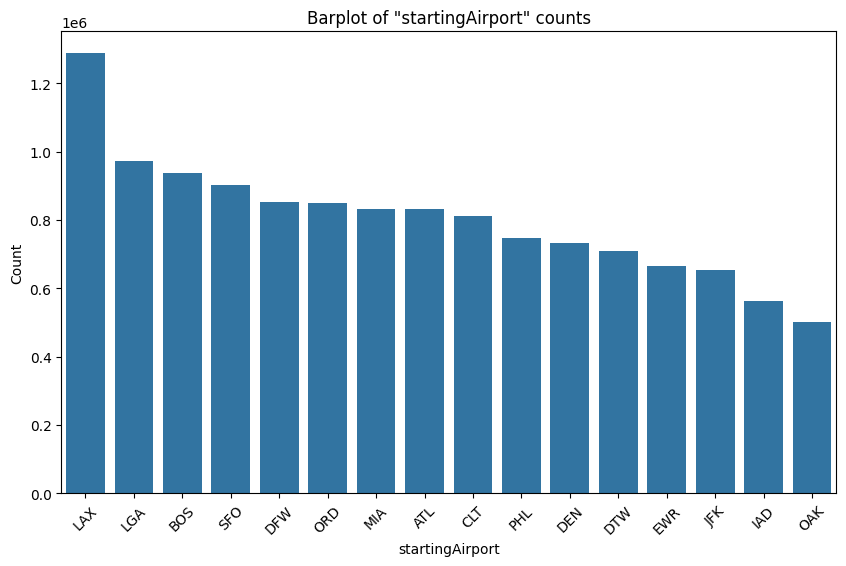

In [32]:
plot_cat_distribution(data=df, column_name="startingAirport")

Количество категорий признака destinationAirport: 16


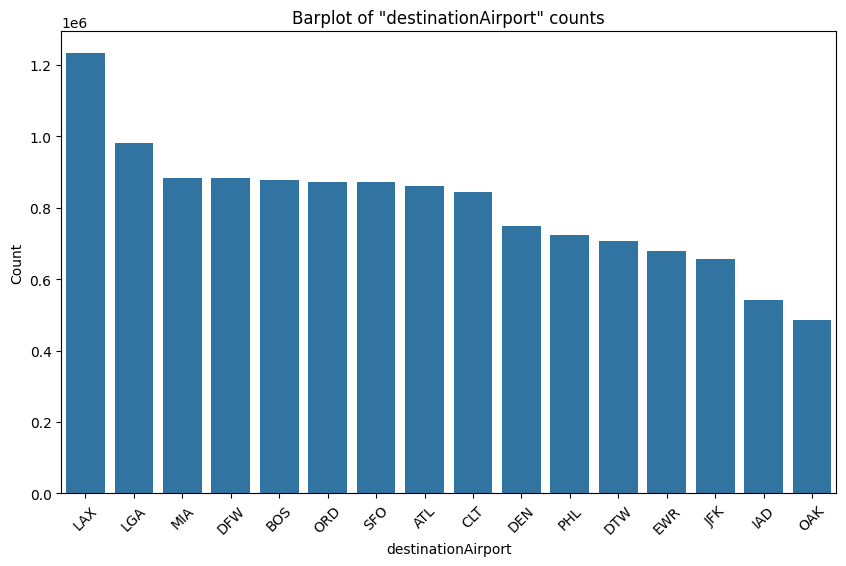

In [33]:
plot_cat_distribution(data=df, column_name="destinationAirport")

Видно, что в каждом из признаков по 16 категорий (аэропортов). Они представлены **неравномерно**: самый частый аэропорт — `LAX` (около 1,3 млн строк вылета и 1,2 млн прилёта), самый редкий — `OAK` (около 0,5 млн строк). Тем не менее даже самая редкая категория содержит сотни тысяч наблюдений, а количество категорий невелико, поэтому дополнительных преобразований не требуется: в лабораторной работе № 2 их можно кодировать стандартными средствами.

#### Анализ столбцов `searchDate` и `flightDate`

Сами по себе даты в модель передавать нецелесообразно. Из них можно получить более содержательные количественные и категориальные признаки:
* `days_to_departure` — количество дней между датой поиска и датой вылета (известный фактор, влияющий на цену билета);
* `flight_dayofweek` — день недели вылета (от 1 — воскресенье до 7 — суббота);
* `flight_month` — месяц вылета.

Исходные столбцы с датами после этого удалим.

In [34]:
count_nulls(data=df, column_name="searchDate")
count_nulls(data=df, column_name="flightDate")

Число строк с NULL: 0 (0.00%)


Число строк с NULL: 0 (0.00%)


Напомним, что в первой части работы мы оставили только данные за один месяц поиска (с 2022-04-16 по 2022-05-17), поэтому датасет охватывает ограниченный период. Уточним его границы до того, как удалим исходные даты.

In [35]:
(
    df
    .select(
        min_("searchDate").alias("search_from"),
        max_("searchDate").alias("search_to"),
        min_("flightDate").alias("flight_from"),
        max_("flightDate").alias("flight_to")
    )
    .show()
)

+-----------+----------+-----------+----------+
|search_from| search_to|flight_from| flight_to|
+-----------+----------+-----------+----------+
| 2022-04-16|2022-05-17| 2022-04-17|2022-07-12|
+-----------+----------+-----------+----------+



Видно, что даты поиска лежат в интервале с 2022-04-16 по 2022-05-17, а даты вылета — с 2022-04-17 по 2022-07-12. Пропусков в датах нет.

In [36]:
df = (
    df
    .withColumn("days_to_departure",
                datediff(col("flightDate"), col("searchDate")))
    .withColumn("flight_dayofweek", dayofweek(col("flightDate")))
    .withColumn("flight_month", month(col("flightDate")))
    .drop("searchDate", "flightDate")
)

Статистика признака "days_to_departure":
  Минимальное значение:          1.00
  Среднее значение:              27.73
  Среднеквадратичное отклонение: 17.30
  Первый квартиль:               12.00
  Медиана:                       26.00
  Третий квартиль:               42.00
  Максимальное значение:         60.00


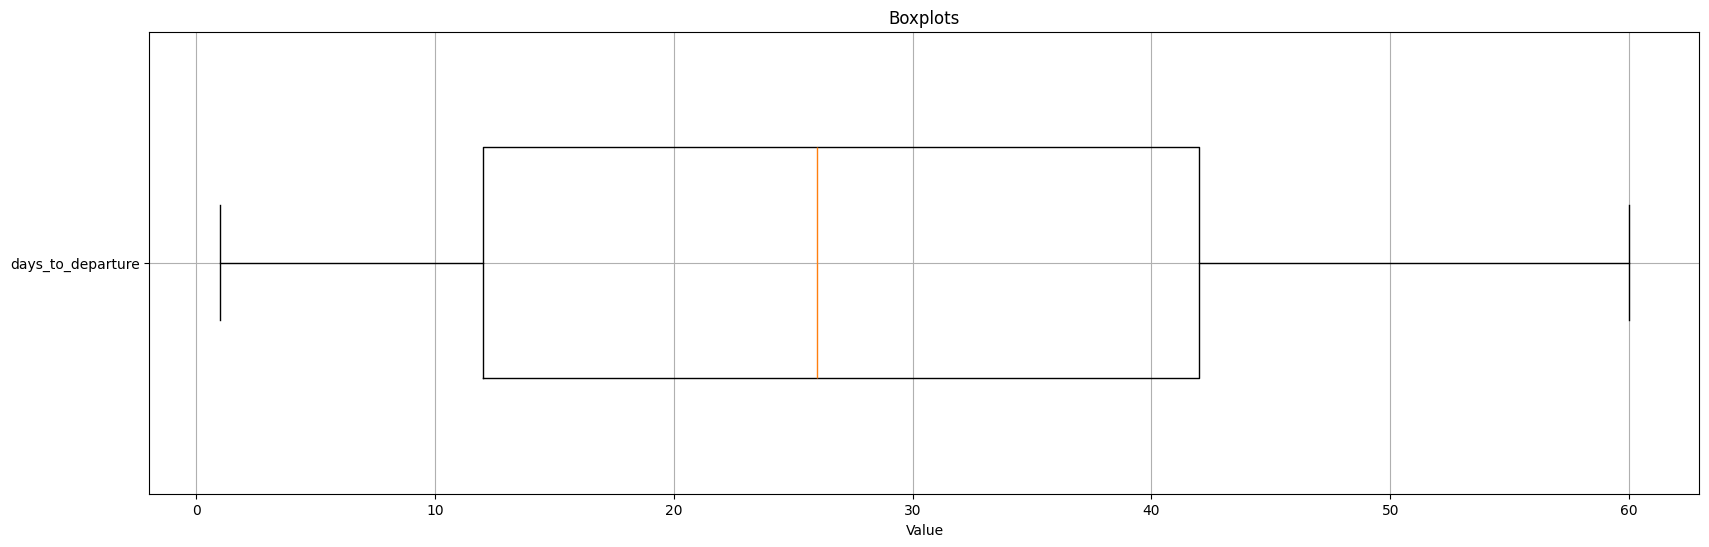

In [37]:
plot_boxplots(data=df, columns=["days_to_departure"])

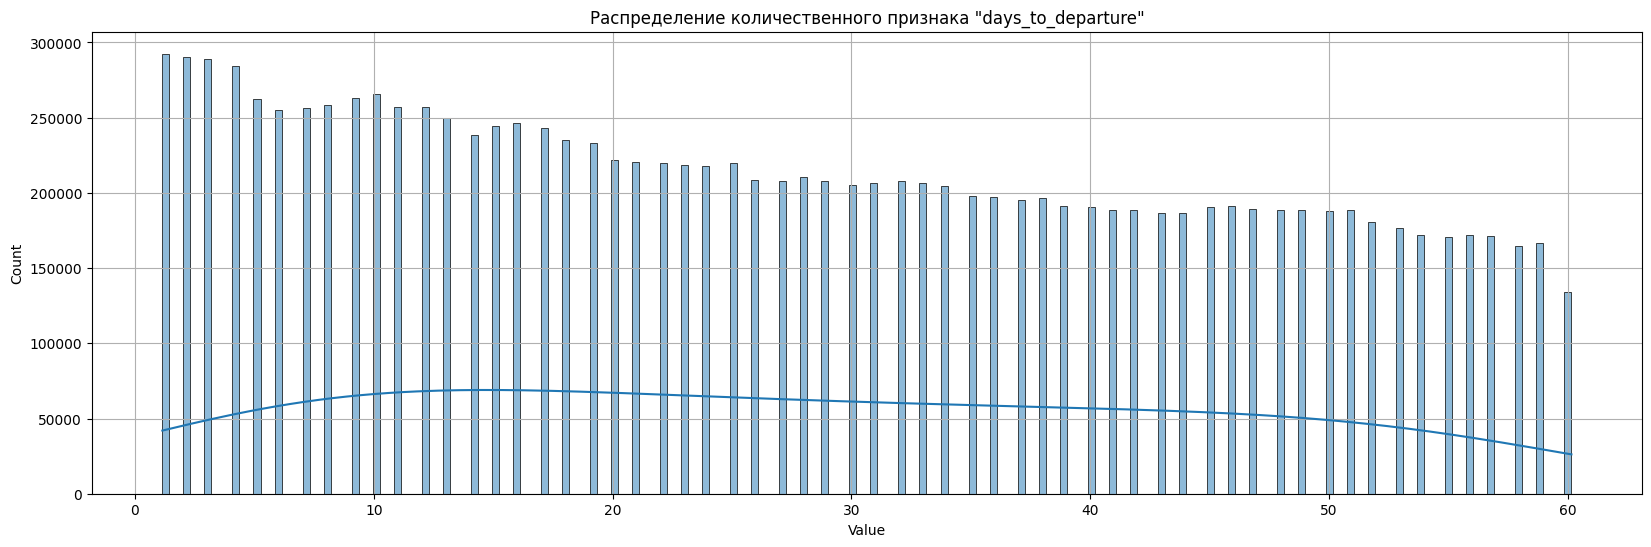

In [38]:
plot_quant_distribution(data=df, column="days_to_departure")

Видно, что `days_to_departure` принимает значения от 1 до 60 дней, среднее значение — около 28 дней, медиана — 26. Выбросов нет: «ящик с усами» охватывает весь диапазон. Количество предложений плавно убывает по мере увеличения срока до вылета: билеты на ближайшие дни искали заметно чаще (около 290 тысяч строк на значения 1–3 дня против 165–190 тысяч на значения 50–59 дней). Спад на значении 60 объясняется тем, что в данных не представлены вылеты позже чем за 60 дней до даты поиска.

Дата вылета не может быть раньше даты поиска. Если подобные строки есть, то это ошибки в данных. Удалим их (вместе со строками, для которых даты не определены).

In [39]:
df = df.filter(col("days_to_departure") >= 0)
count_nulls(data=df, column_name="days_to_departure")

Число строк с NULL: 0 (0.00%)


Видно, что пропусков нет, поэтому на этом этапе ни одна строка не удалена.

Количество категорий признака flight_dayofweek: 7


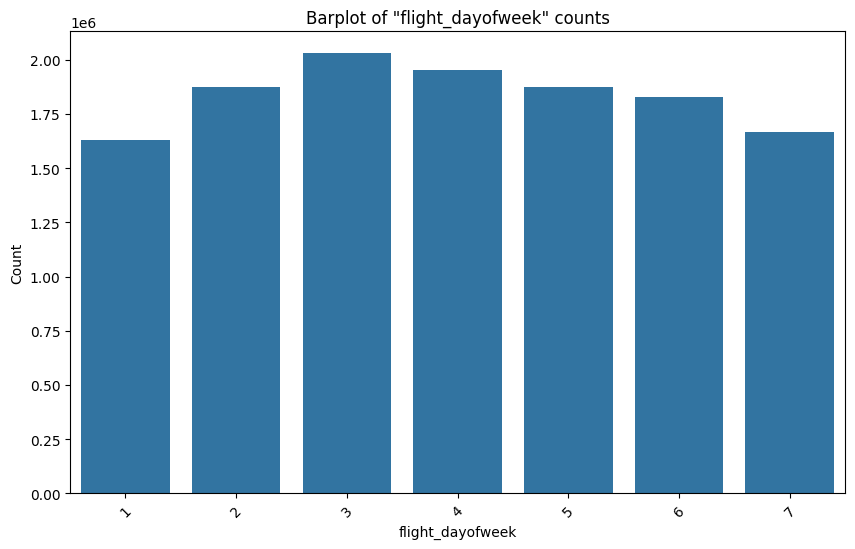

In [40]:
plot_cat_distribution(data=df, column_name="flight_dayofweek")

Количество категорий признака flight_month: 4


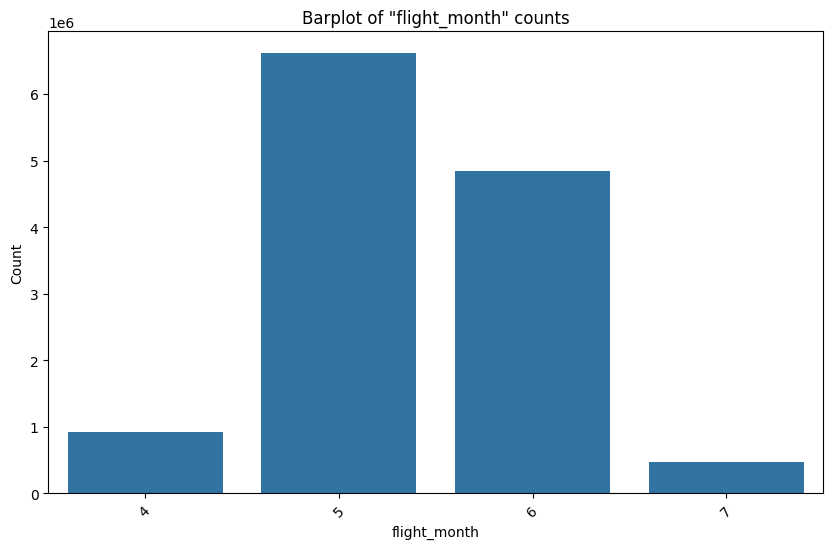

In [41]:
plot_cat_distribution(data=df, column_name="flight_month")

Видно, что вылеты распределены по дням недели достаточно равномерно: чаще всего вылетают во вторник (значение 3, около 2,0 млн строк), реже всего — в воскресенье (значение 1, около 1,6 млн строк). По месяцам вылета распределение сильно неравномерное: больше всего вылетов в мае (около 6,6 млн строк) и июне (около 4,8 млн), мало в апреле (около 0,9 млн) и июле (около 0,5 млн). Это объясняется способом формирования выборки: мы взяли месяц поиска (16 апреля — 17 мая), а билеты ищут преимущественно на ближайшие недели, поэтому апрель и июль оказались «краями» диапазона.

Признаки `flight_dayofweek` и `flight_month` являются категориальными (порядковыми) и имеют небольшое число значений.

In [42]:
df.show(5, truncate=40)

+--------------------------------+---------------+------------------+-----------+--------------+------------+---------+---------+--------------+-------------------+----------------------------------------+--------------------------------------+-----------------+-------------------+-----------------+----------------+------------+
|                           legId|startingAirport|destinationAirport|elapsedDays|isBasicEconomy|isRefundable|isNonStop|totalFare|seatsRemaining|totalTravelDistance|                segmentsDepartureTimeRaw|                   segmentsAirlineName|segmentsCabinCode|travel_duration_min|days_to_departure|flight_dayofweek|flight_month|
+--------------------------------+---------------+------------------+-----------+--------------+------------+---------+---------+--------------+-------------------+----------------------------------------+--------------------------------------+-----------------+-------------------+-----------------+----------------+------------+
|a0ae8d

#### Анализ столбца `travel_duration_min`

Признак количественный: общая длительность поездки в минутах (включая время ожидания пересадок).

In [43]:
count_nulls(data=df, column_name="travel_duration_min")

Число строк с NULL: 3 (0.00%)


Статистика признака "travel_duration_min":
  Минимальное значение:          46.00
  Среднее значение:              418.01
  Среднеквадратичное отклонение: 221.54
  Первый квартиль:               248.00
  Медиана:                       396.00
  Третий квартиль:               553.00
  Максимальное значение:         2566.00


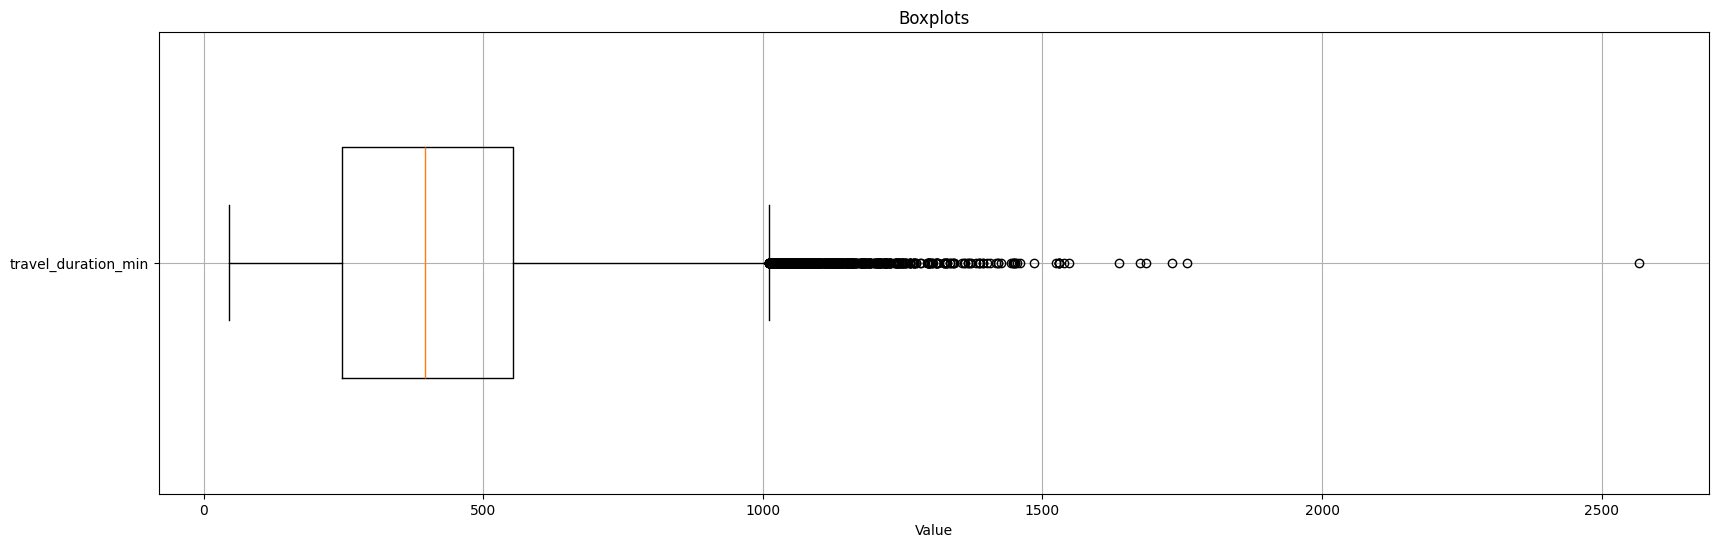

In [44]:
plot_boxplots(data=df, columns=["travel_duration_min"])

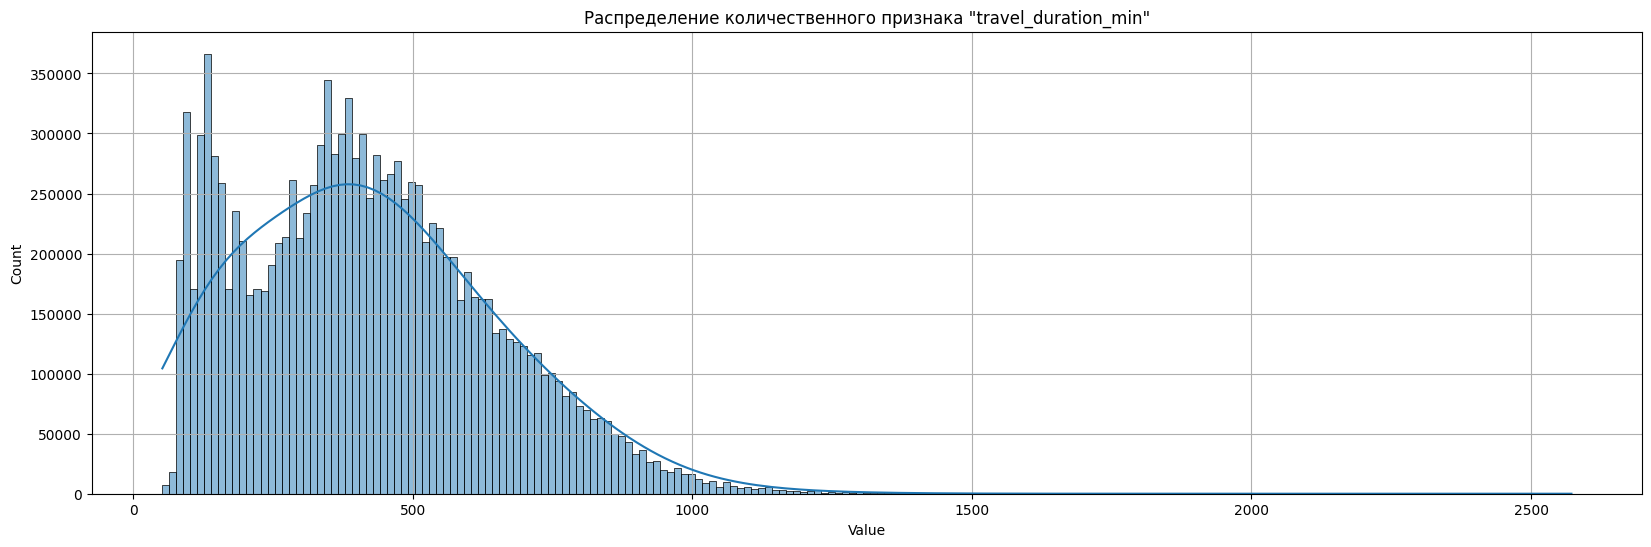

In [45]:
plot_quant_distribution(data=df, column="travel_duration_min")

Распределение имеет длинный правый «хвост»: небольшая часть перелётов с несколькими пересадками длится очень долго. Оценим, какую долю данных мы потеряем, если удалим строки выше 99,5-го процентиля, и удалим их. Заодно удалим строки с пропущенной или неположительной длительностью.

Граница (99,5-й процентиль), мин: 972.0


Строк выше границы: 72242


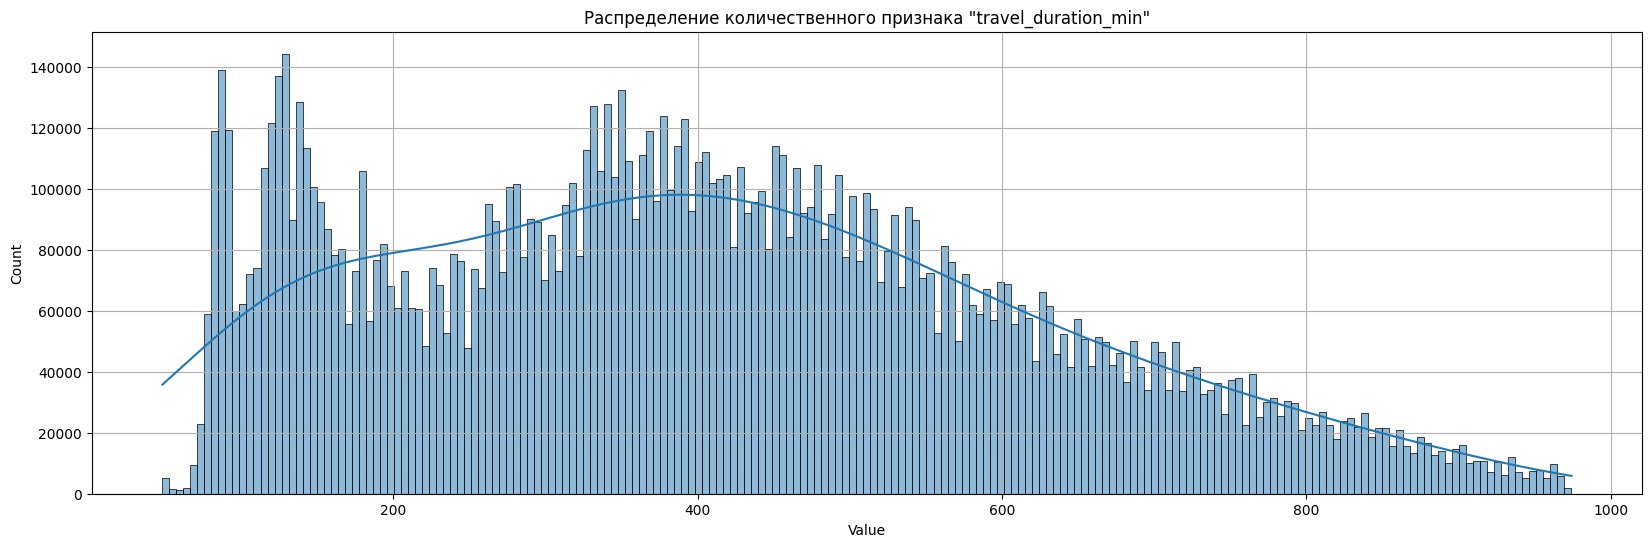

In [93]:
duration_upper = get_upper_quantile(df, "travel_duration_min", q=0.995)
print(f"Граница (99,5-й процентиль), мин: {duration_upper}")
print(f"Строк выше границы: {df.filter(col('travel_duration_min') > duration_upper).count()}")

df = df.filter(
    (col("travel_duration_min") > 0) &
    (col("travel_duration_min") <= duration_upper)
)
plot_quant_distribution(data=df, column="travel_duration_min")

Видно, что распределение длительности имеет два пика: около 100–150 минут (прямые рейсы) и около 350–450 минут (рейсы с одной пересадкой). Медиана равна 396 минутам (6,6 часа), среднее — 418 минутам. Максимальное значение (2566 минут, около 43 часов) является явным выбросом. Граница по 99,5-му процентилю составила 1051 минуту (около 17,5 часа); за ней находились 74 051 строк (около 0,6 %), которые были удалены вместе с тремя строками с пропущенной длительностью. После этого распределение стало более компактным, а «хвост» — плавно затухающим.

#### Анализ столбца `elapsedDays`

Признак показывает, сколько суток прошло между вылетом и прилётом. Он целочисленный, но принимает мало значений.

In [47]:
count_nulls(data=df, column_name="elapsedDays")

Число строк с NULL: 0 (0.00%)


Количество категорий признака elapsedDays: 2


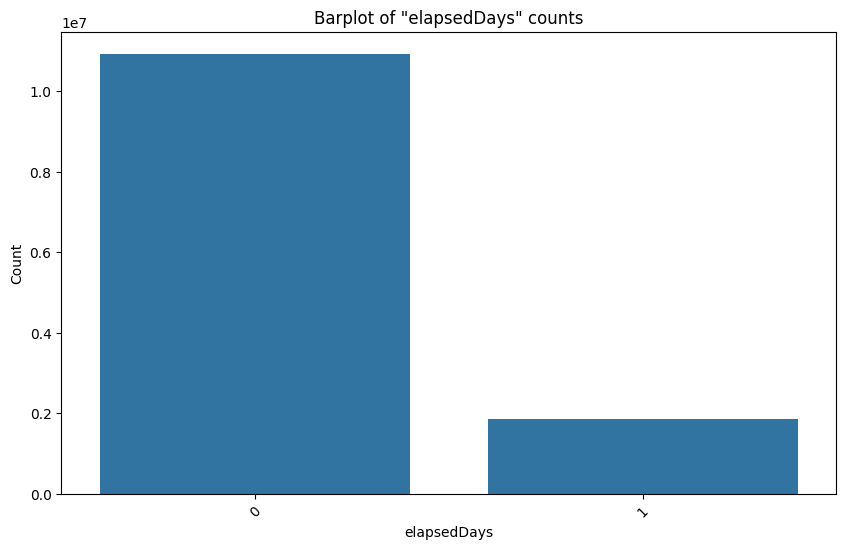

In [48]:
plot_cat_distribution(data=df, column_name="elapsedDays")

Видно, что у около 85 % строк значение равно нулю (прилёт в день вылета), а у около 15 % — единице (прилёт на следующий день, например, ночные рейсы и перелёты с долгими пересадками). Других значений нет. Поэтому нет смысла рассматривать количество суток как количественный признак. Заменим его бинарным признаком `arrives_later_day`, принимающим значение `True`, если прилёт происходит не в день вылета. Пропущенные значения при этом будут интерпретированы как `False`.

In [49]:
df = df.withColumn(
    "arrives_later_day",
    when(col("elapsedDays") > 0, True).otherwise(False)
).drop("elapsedDays")

Количество категорий признака arrives_later_day: 2


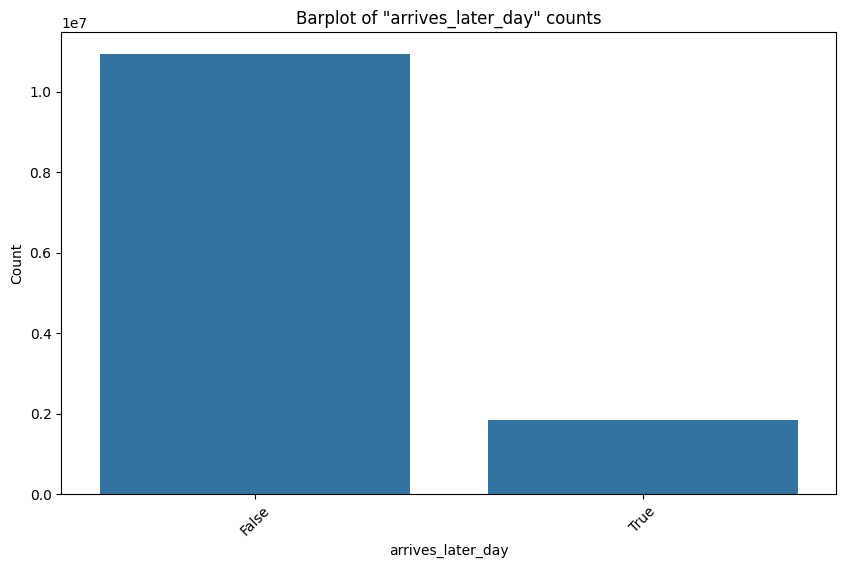

In [50]:
plot_cat_distribution(data=df, column_name="arrives_later_day")

#### Анализ столбца `isBasicEconomy`

Признак бинарный. Именно он будет целевой переменной в задаче бинарной классификации в лабораторной работе № 2.

In [51]:
count_nulls(data=df, column_name="isBasicEconomy")

Число строк с NULL: 0 (0.00%)


Оценим распределение классов.

In [52]:
df.groupBy("isBasicEconomy").count().show()

basic_share = df.select(mean(col("isBasicEconomy").cast("int"))).first()[0]
print(f"Доля билетов базовой экономии: {100 * basic_share:.2f}%")

+--------------+--------+
|isBasicEconomy|   count|
+--------------+--------+
|          true|  721606|
|         false|12061650|
+--------------+--------+



Доля билетов базовой экономии: 5.64%


Количество категорий признака isBasicEconomy: 2


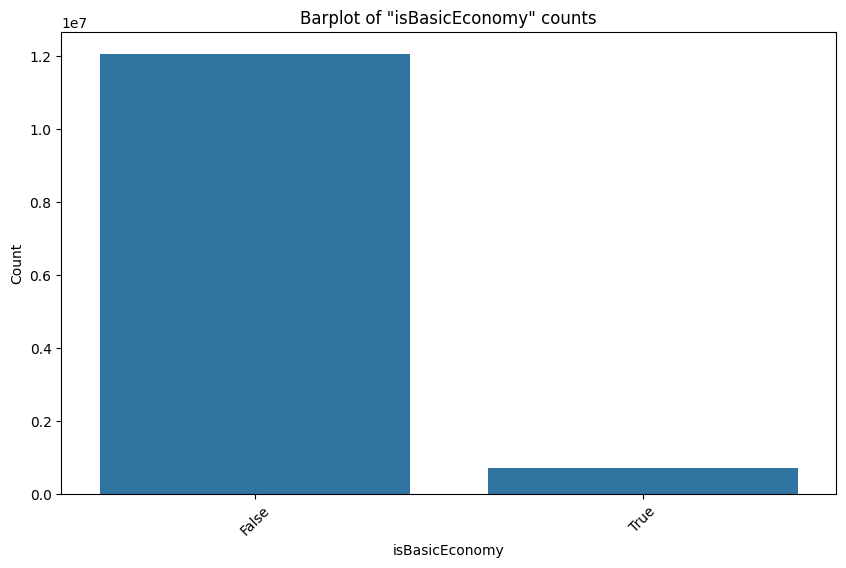

In [53]:
plot_cat_distribution(data=df, column_name="isBasicEconomy")

Видно, что билеты базовой экономии составляют всего 5,64 % данных (721 606 строк против 12 061 650). Соотношение классов примерно 1 к 17, то есть датасет сильно несбалансирован. Это необходимо будет учесть при обучении модели классификации: балансировать обучающую выборку (например, увеличив число объектов малого класса) или задавать веса классов, а качество оценивать метриками, устойчивыми к дисбалансу (`precision`, `recall`, `F1`, `ROC AUC`). Модель, всегда отвечающая «не базовая экономия», имела бы точность около 94,4 %, но была бы бесполезной.

#### Анализ столбца `isRefundable`

Признак бинарный.

In [54]:
count_nulls(data=df, column_name="isRefundable")

Число строк с NULL: 0 (0.00%)


In [55]:
df.groupBy("isRefundable").count().show()

+------------+--------+
|isRefundable|   count|
+------------+--------+
|       false|12783084|
|        true|     172|
+------------+--------+



Признак, у которого почти все значения одинаковы, не несёт полезной информации для модели. Оценим долю значений `True`. Если она меньше 1% (или больше 99%), удалим признак. В противном случае сохраним его, заполнив пропуски значением `False`.

In [56]:
refundable_share = df.select(
    mean(col("isRefundable").cast("int"))
).first()[0]
print(f"Доля возвращаемых билетов: {100 * refundable_share:.2f}%")

if refundable_share < 0.01 or refundable_share > 0.99:
    df = df.drop("isRefundable")
    print("Признак практически константен, столбец isRefundable удалён")
else:
    df = df.fillna({"isRefundable": False})
    print("Признак сохранён, пропуски заполнены значением False")

Доля возвращаемых билетов: 0.00%
Признак практически константен, столбец isRefundable удалён


Видно, что возвращаемых билетов в данных всего 172 из почти 12,8 млн (около 0,001 %), поэтому признак `isRefundable` практически константен и был удален.

#### Анализ столбца `isNonStop` и признак `num_stops`

Признак `isNonStop` бинарный и показывает, является ли перелёт прямым. Пропусков, как правило, нет, но проверим это.

In [57]:
count_nulls(data=df, column_name="isNonStop")

Число строк с NULL: 0 (0.00%)


Столбцы с информацией о сегментах перелёта теперь содержат массивы: каждый элемент массива соответствует одному сегменту. Количество сегментов дает нам точное число пересадок: `num_stops = количество сегментов - 1`. Это не только позволяет различать перелёты с одной, двумя и более пересадками, но и дает возможность проверить корректность признака `isNonStop`: он должен быть истинным только для перелётов, состоящих из одного сегмента.

In [58]:
df = df.withColumn("num_stops", size(col("segmentsDepartureTimeRaw")) - 1)

inconsistent_count = df.filter(
    col("isNonStop") != (col("num_stops") == 0)
).count()
print(f"Строк, в которых isNonStop противоречит числу сегментов: {inconsistent_count}")

Строк, в которых isNonStop противоречит числу сегментов: 0


Удалим строки с противоречивыми значениями (а также строки, в которых `isNonStop` не определён).

Количество категорий признака isNonStop: 2


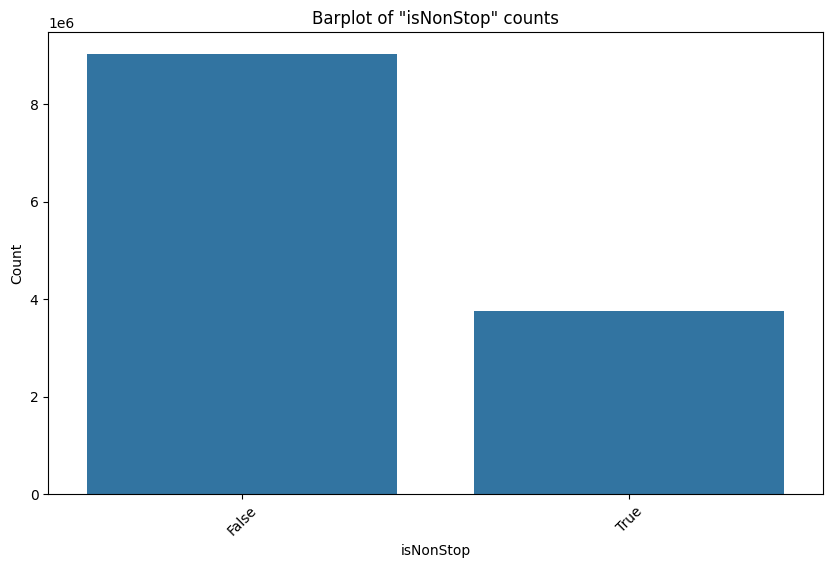

Количество категорий признака num_stops: 4


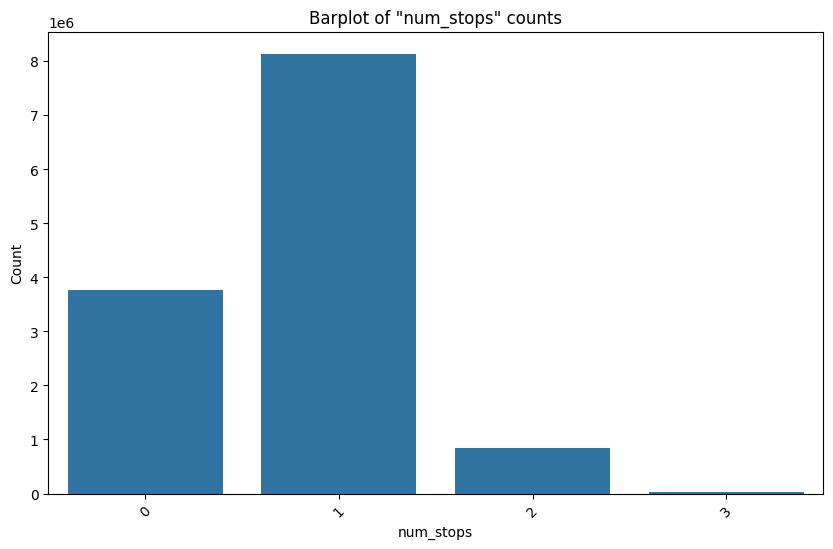

In [59]:
df = df.filter(col("isNonStop") == (col("num_stops") == 0))
plot_cat_distribution(data=df, column_name="isNonStop")
plot_cat_distribution(data=df, column_name="num_stops")

Перелёты с большим количеством пересадок встречаются редко. Объединим их в одну категорию «2 и более пересадок».

Количество категорий признака num_stops: 3


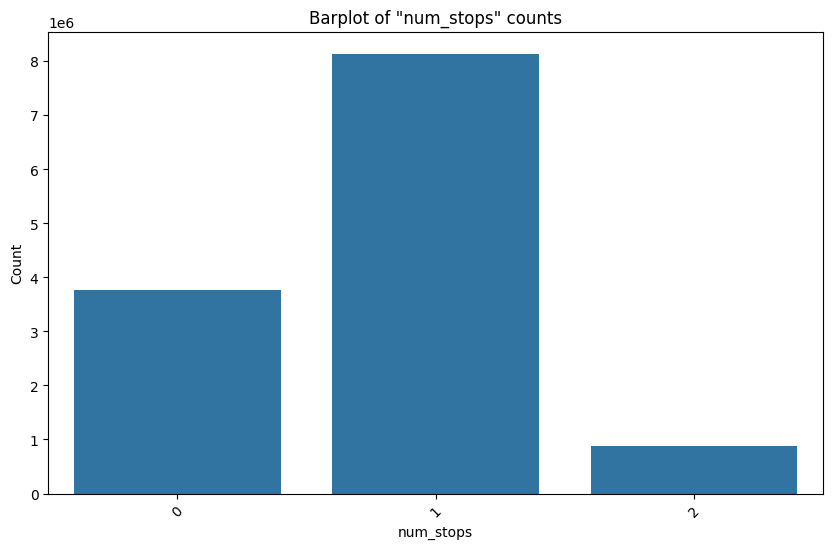

In [60]:
df = df.withColumn(
    "num_stops",
    when(col("num_stops") >= 2, 2).otherwise(col("num_stops"))
)
plot_cat_distribution(data=df, column_name="num_stops")

Видно, что наиболее частыми являются перелёты с одной пересадкой (около 8,1 млн строк, примерно 64 %), затем идут прямые рейсы (около 3,8 млн, примерно 30 %) и перелёты с двумя и более пересадками (около 0,85 млн, примерно 7 %). Признак `isNonStop` полностью согласуется с числом пересадок (ни одного противоречия), и прямых рейсов столько же, сколько строк с `num_stops = 0`.

#### Анализ столбца `segmentsDepartureTimeRaw`: час вылета

Из массива времён вылета возьмем время вылета первого сегмента — то есть время вылета из исходного аэропорта — и выделим из него час вылета `departure_hour` по местному времени. Время записано в формате `YYYY-MM-DDThh:mm:ss.000±hh:00`, поэтому час — это 12-й и 13-й символы строки.

In [61]:
df = df.withColumn(
    "departure_hour",
    substring(col("segmentsDepartureTimeRaw")[0], 12, 2).cast("Integer")
).drop("segmentsDepartureTimeRaw")

count_nulls(data=df, column_name="departure_hour")

Число строк с NULL: 0 (0.00%)


Количество категорий признака departure_hour: 21


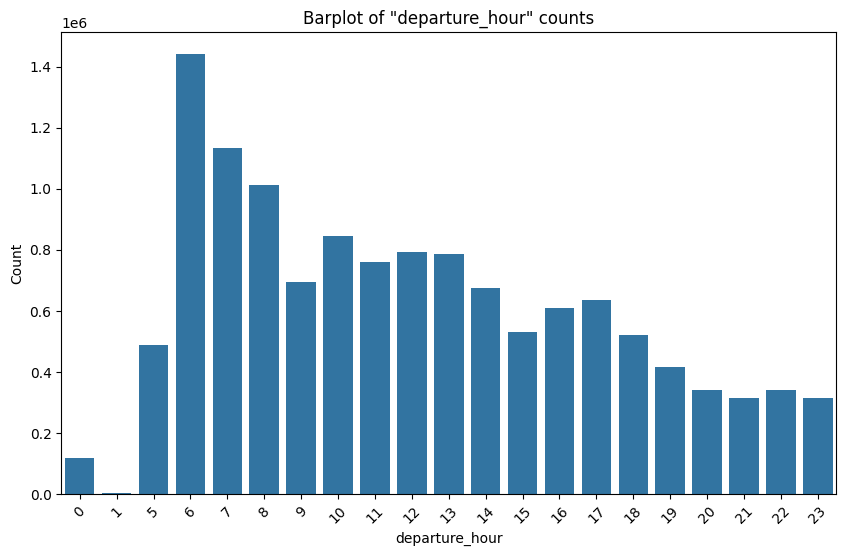

In [62]:
df = df.filter((col("departure_hour") >= 0) & (col("departure_hour") <= 23))
plot_cat_distribution(data=df, column_name="departure_hour", top_n=24)

Видно, что в данных присутствуют 21 значение часа вылета: от 0 до 23, кроме 2, 3 и 4 часов ночи (в это время рейсов практически нет, а час 1 представлен единичными рейсами). Пик вылетов приходится на 6 часов утра (около 1,4 млн строк), затем интенсивность плавно снижается к вечеру. Пропусков и некорректных значений нет.

Признак `departure_hour` — количественный дискретный (значения от 0 до 23).

#### Анализ столбца `segmentsAirlineName`: авиакомпания

Для перелётов с пересадками авиакомпании на разных сегментах могут отличаться. В качестве признака `main_airline` будем использовать авиакомпанию, выполняющую первый сегмент перелёта. Признак категориальный.

In [63]:
df = df.withColumn("main_airline", col("segmentsAirlineName")[0])
df = df.drop("segmentsAirlineName")

count_nulls(data=df, column_name="main_airline")

Число строк с NULL: 0 (0.00%)


Посмотрим на распределение.

Количество категорий признака main_airline: 14


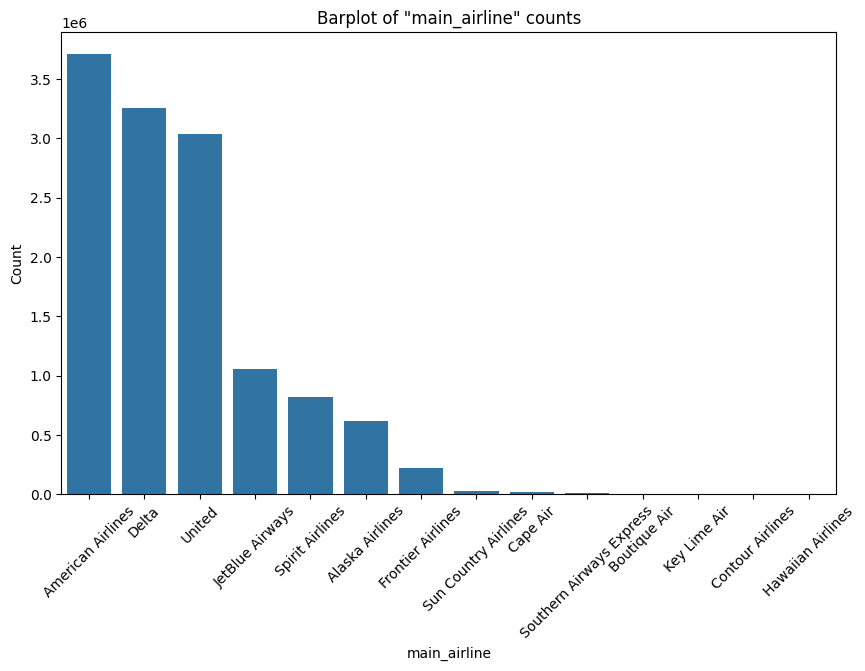

In [64]:
plot_cat_distribution(data=df, column_name="main_airline")

Видно, что в данных присутствует 14 авиакомпаний, но основную массу составляют три: `American Airlines` (около 3,7 млн строк), `Delta` (около 3,3 млн) и `United` (около 3,0 млн). Затем идут `JetBlue Airways`, `Spirit Airlines`, `Alaska Airlines` и `Frontier Airlines`. Остальные авиакомпании встречаются крайне редко. Объединим редкие категории в одну категорию `Other`, оставив восемь самых частых.

In [65]:
def group_rare_categories(data: DataFrame,
                          column: str,
                          top_n: int = 8) -> DataFrame:
    """
    Заменяет редкие категории признака на категорию "Other", оставляя
    только top_n самых частых значений.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column (str): Имя категориального столбца.
        top_n (int): Количество сохраняемых категорий.

    Returns:
        DataFrame: DataFrame с объединенными редкими категориями.
    """
    top_categories = [
        row[0] for row in (
            data
            .groupBy(column)
            .count()
            .orderBy(desc("count"))
            .limit(top_n)
            .collect()
        )
    ]
    return data.withColumn(
        column,
        when(col(column).isin(top_categories), col(column))
        .otherwise(lit("Other"))
    )

Количество категорий признака main_airline: 9


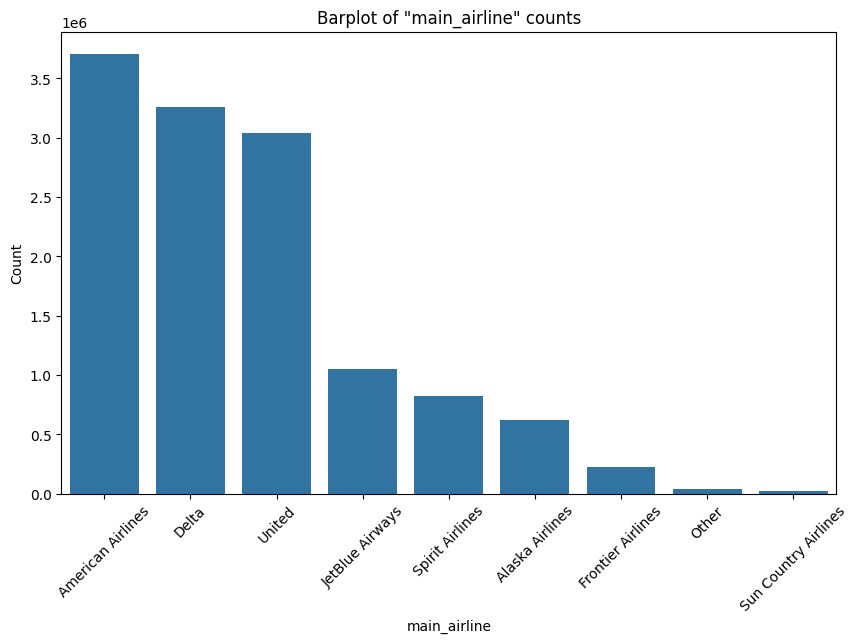

In [66]:
df = group_rare_categories(data=df, column="main_airline", top_n=8)
plot_cat_distribution(data=df, column_name="main_airline")

Видно, что после объединения осталось 9 категорий: восемь крупнейших авиакомпаний и категория `Other`, в которую вошли шесть малых перевозчиков (`Cape Air`, `Southern Airways Express`, `Boutique Air`, `Key Lime Air`, `Contour Airlines`, `Hawaiian Airlines`). Категория `Other` включает лишь небольшую долю данных, поэтому информация почти не теряется.

#### Анализ столбца `segmentsCabinCode`: класс обслуживания

Аналогично авиакомпании, в качестве признака `main_cabin` возьмем класс обслуживания на первом сегменте перелёта. Признак категориальный.

In [67]:
df = df.withColumn("main_cabin", col("segmentsCabinCode")[0])
df = df.drop("segmentsCabinCode")

count_nulls(data=df, column_name="main_cabin")

Число строк с NULL: 0 (0.00%)


Количество категорий признака main_cabin: 4


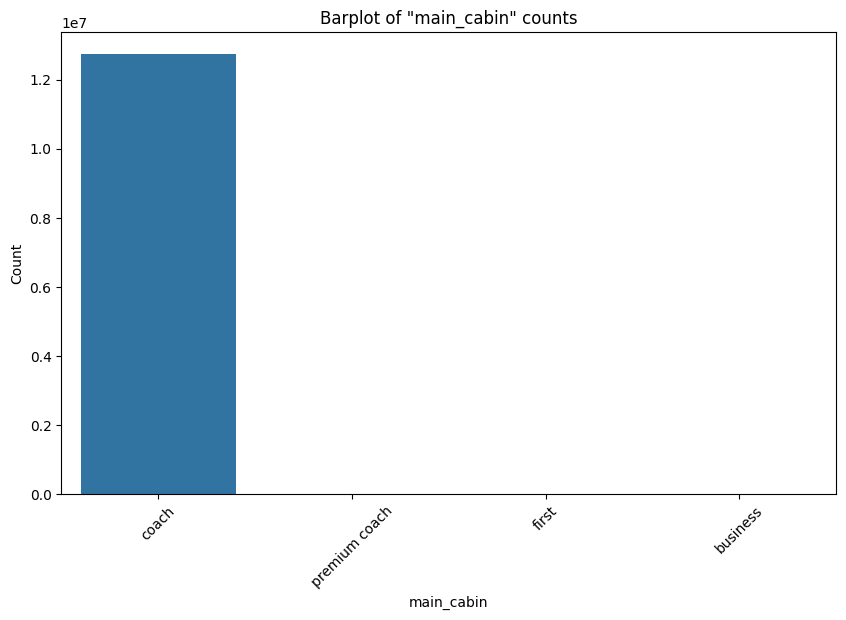

In [68]:
plot_cat_distribution(data=df, column_name="main_cabin")

Видно, что класс обслуживания `coach` встречается практически во всех строках, а остальные три класса (`premium coach`, `first`, `business`) представлены ничтожным количеством строк. Признак с практически одинаковым значением почти не несёт информации для моделей, а при `one-hot`-кодировании дал бы три столбца, состоящие почти целиком из нулей. Поэтому, как и в случае с `isRefundable`, оценим долю самого частого значения и при превышении 99 % удалим признак.

Оценим долю класса `coach`. Если она превышает 99 %, признак `main_cabin` практически константен и будет удален.

In [69]:
coach_share = df.select(
    mean((col("main_cabin") == "coach").cast("int"))
).first()[0]
print(f"Доля класса coach: {100 * coach_share:.3f}%")

if coach_share > 0.99:
    df = df.drop("main_cabin")
    print("Признак практически константен, столбец main_cabin удалён")
else:
    print("Признак сохранён")

Доля класса coach: 99.656%
Признак практически константен, столбец main_cabin удалён


In [70]:
df = df.cache()
df.show(5, truncate=40)

+--------------------------------+---------------+------------------+--------------+---------+---------+--------------+-------------------+-------------------+-----------------+----------------+------------+-----------------+---------+--------------+-----------------+
|                           legId|startingAirport|destinationAirport|isBasicEconomy|isNonStop|totalFare|seatsRemaining|totalTravelDistance|travel_duration_min|days_to_departure|flight_dayofweek|flight_month|arrives_later_day|num_stops|departure_hour|     main_airline|
+--------------------------------+---------------+------------------+--------------+---------+---------+--------------+-------------------+-------------------+-----------------+----------------+------------+-----------------+---------+--------------+-----------------+
|a0ae8d5727fd9f58d23ec3469b0bf2d1|            PHL|               ATL|         false|    false|   346.11|             3|              677.0|                247|               25|               6

#### Анализ столбца `seatsRemaining`

Признак количественный дискретный (количество оставшихся мест).

In [71]:
count_nulls(data=df, column_name="seatsRemaining")

Число строк с NULL: 0 (0.00%)


Количество категорий признака seatsRemaining: 11


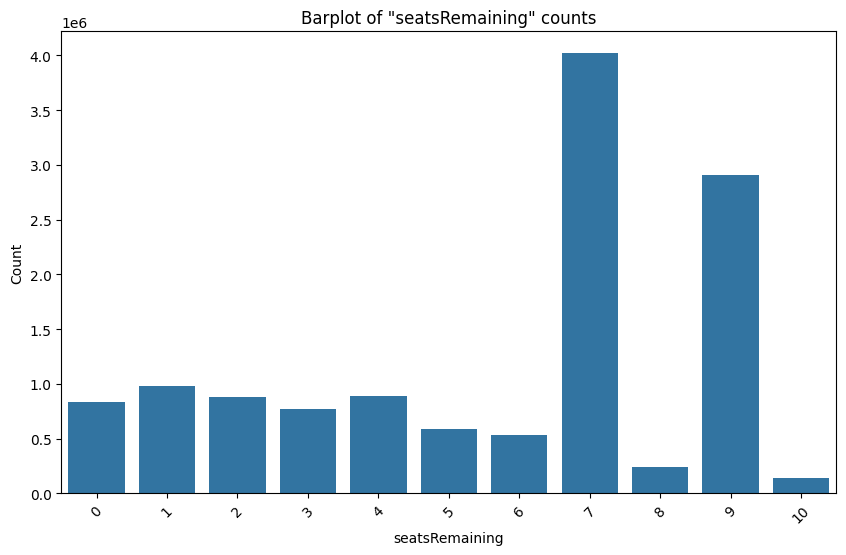

In [72]:
plot_cat_distribution(data=df, column_name="seatsRemaining")

Значения принимают небольшой диапазон целых чисел.

Количество категорий признака seatsRemaining: 11


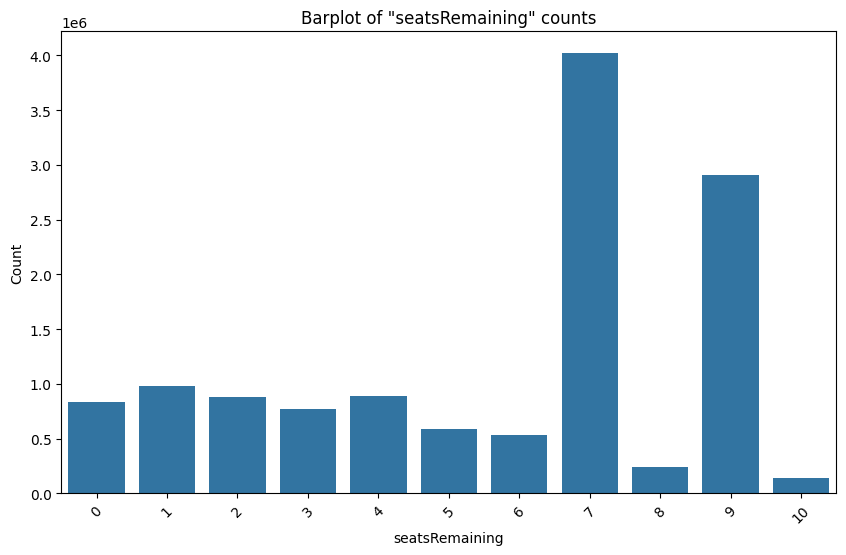

In [73]:
plot_cat_distribution(data=df, column_name="seatsRemaining")

Видно, что `seatsRemaining` принимает целые значения от 0 до 10. Распределение нетипично: резко выделяются значения 7 (около 4,0 млн строк) и 9 (около 2,9 млн), а значения 8 и 10 встречаются редко. Вероятно, это особенность того, как `Expedia` отображает количество мест, но точную причину по данным установить нельзя. Также около 0,85 млн строк (примерно 6–7 %) имеют значение 0, хотя билет присутствует в выдаче; мы не можем однозначно считать это ошибкой, поэтому такие строки оставлены. В целом признак имеет слабую связь с целевыми переменными.

#### Анализ столбца `totalTravelDistance`

Признак количественный. Согласно описанию датасета, он иногда отсутствует.

In [74]:
count_nulls(data=df, column_name="totalTravelDistance")

Число строк с NULL: 874504 (6.84%)


Дальность перелёта в первую очередь определяется маршрутом: аэропортами вылета и прилёта и числом пересадок. Поэтому пропуски разумнее заполнять не глобальным средним, а медианой по маршруту (`startingAirport`, `destinationAirport`, `num_stops`). Если для какого-то маршрута нет ни одного известного значения, воспользуемся общей медианой.

In [75]:
route_keys = ["startingAirport", "destinationAirport", "num_stops"]

route_median = (
    df
    .filter(col("totalTravelDistance").isNotNull())
    .groupBy(route_keys)
    .agg(percentile_approx("totalTravelDistance", 0.5).alias("route_median_distance"))
)

global_median_distance = df.approxQuantile("totalTravelDistance", [0.5], 0.01)[0]
print(f"Общая медиана дальности: {global_median_distance}")

df = (
    df
    .join(route_median.hint("broadcast"), on=route_keys, how="left")
    .withColumn(
        "totalTravelDistance",
        coalesce(col("totalTravelDistance"),
                 col("route_median_distance"),
                 lit(global_median_distance)).cast("Float")
    )
    .drop("route_median_distance")
)

count_nulls(data=df, column_name="totalTravelDistance")

Общая медиана дальности: 1392.0


Число строк с NULL: 0 (0.00%)


Видно, что в `totalTravelDistance` было 874 504 пропуска (6,84 %), которые теперь заполнены медианой по маршруту (аэропорты вылета и прилёта и число пересадок). Общая медиана дальности (1392 мили) использовалась бы только для маршрутов, у которых нет ни одного известного значения. После заполнения пропусков не осталось. Дальность варьируется от 97 до 4430 миль при медиане 1392 мили.

Статистика признака "totalTravelDistance":
  Минимальное значение:          97.00
  Среднее значение:              1558.60
  Среднеквадратичное отклонение: 825.13
  Первый квартиль:               868.00
  Медиана:                       1392.00
  Третий квартиль:               2307.00
  Максимальное значение:         4430.00


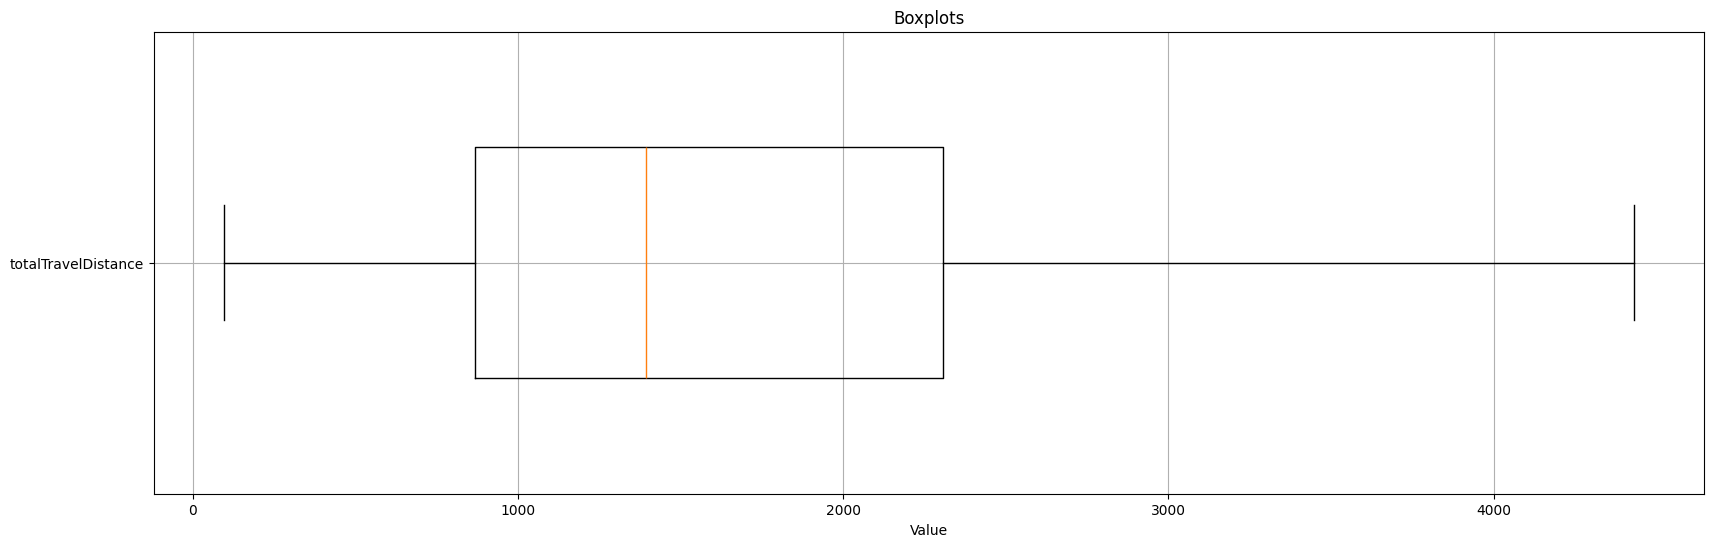

In [76]:
plot_boxplots(data=df, columns=["totalTravelDistance"])

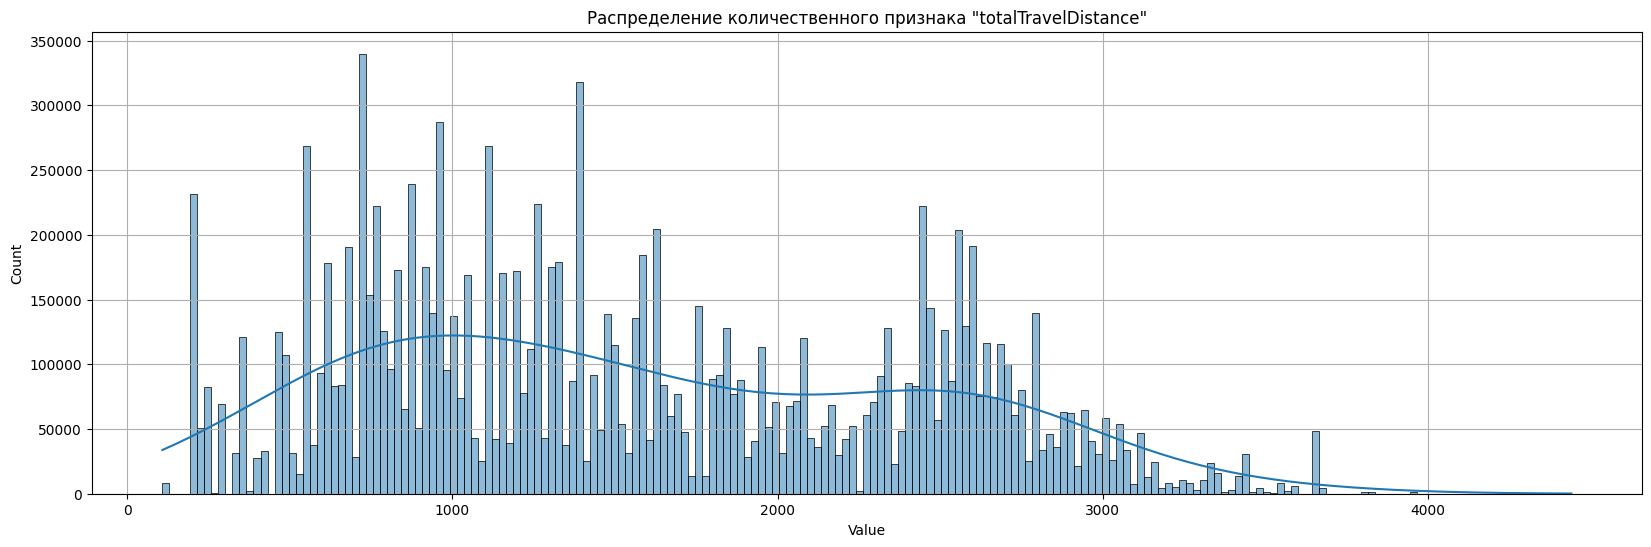

In [77]:
plot_quant_distribution(data=df, column="totalTravelDistance")

Удалим строки с неположительной дальностью и сильные выбросы выше 99,5-го процентиля.

Граница (99,5-й процентиль), миль: 3513.0


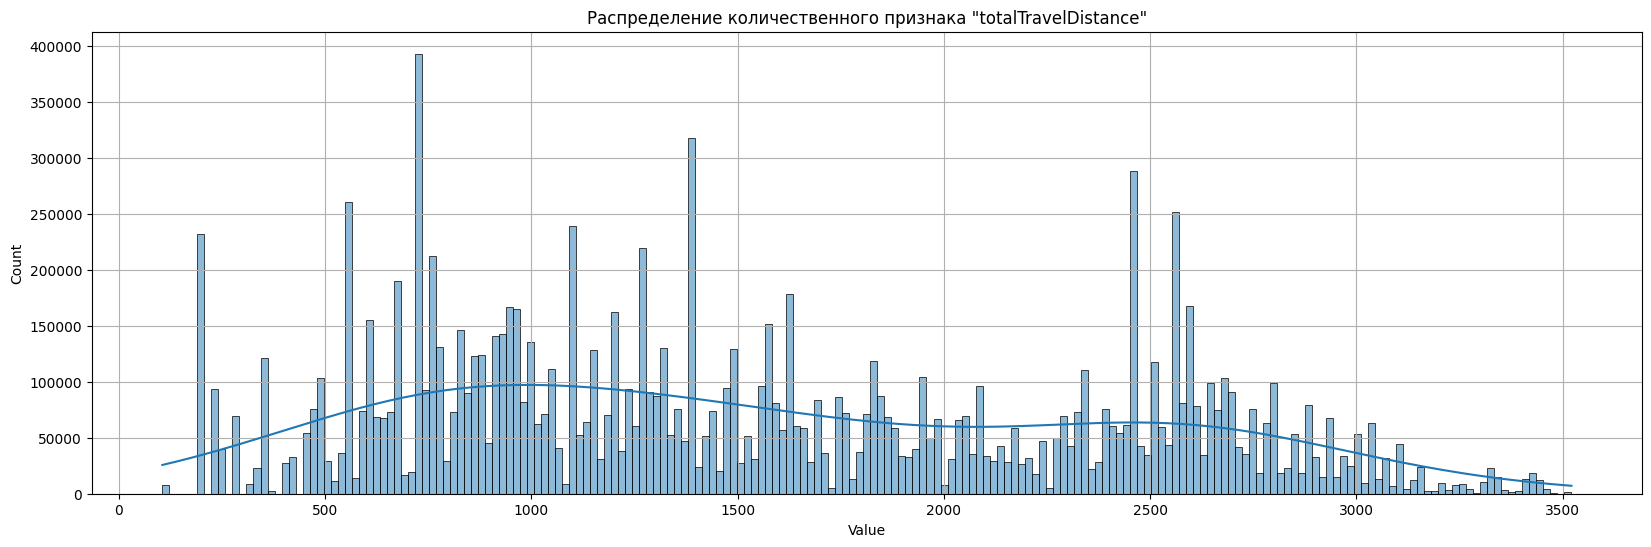

In [78]:
distance_upper = get_upper_quantile(df, "totalTravelDistance", q=0.995)
print(f"Граница (99,5-й процентиль), миль: {distance_upper}")

df = df.filter(
    (col("totalTravelDistance") > 0) &
    (col("totalTravelDistance") <= distance_upper)
)
plot_quant_distribution(data=df, column="totalTravelDistance")

Видно, что граница по 99,5-му процентилю составила 3513 миль; строки с большей дальностью (самые длинные маршруты) были удалены. На гистограмме видны отдельные «пики»: это популярные маршруты, дальность которых фиксирована, поэтому распределение не является гладким.

#### Анализ столбца `totalFare`

Признак количественный. Именно он будет целевой переменной в задаче линейной регрессии в лабораторной работе № 2.

In [79]:
count_nulls(data=df, column_name="totalFare")

Число строк с NULL: 0 (0.00%)


Статистика признака "totalFare":
  Минимальное значение:          23.97
  Среднее значение:              370.21
  Среднеквадратичное отклонение: 206.21
  Первый квартиль:               219.58
  Медиана:                       338.60
  Третий квартиль:               478.10
  Максимальное значение:         8260.61


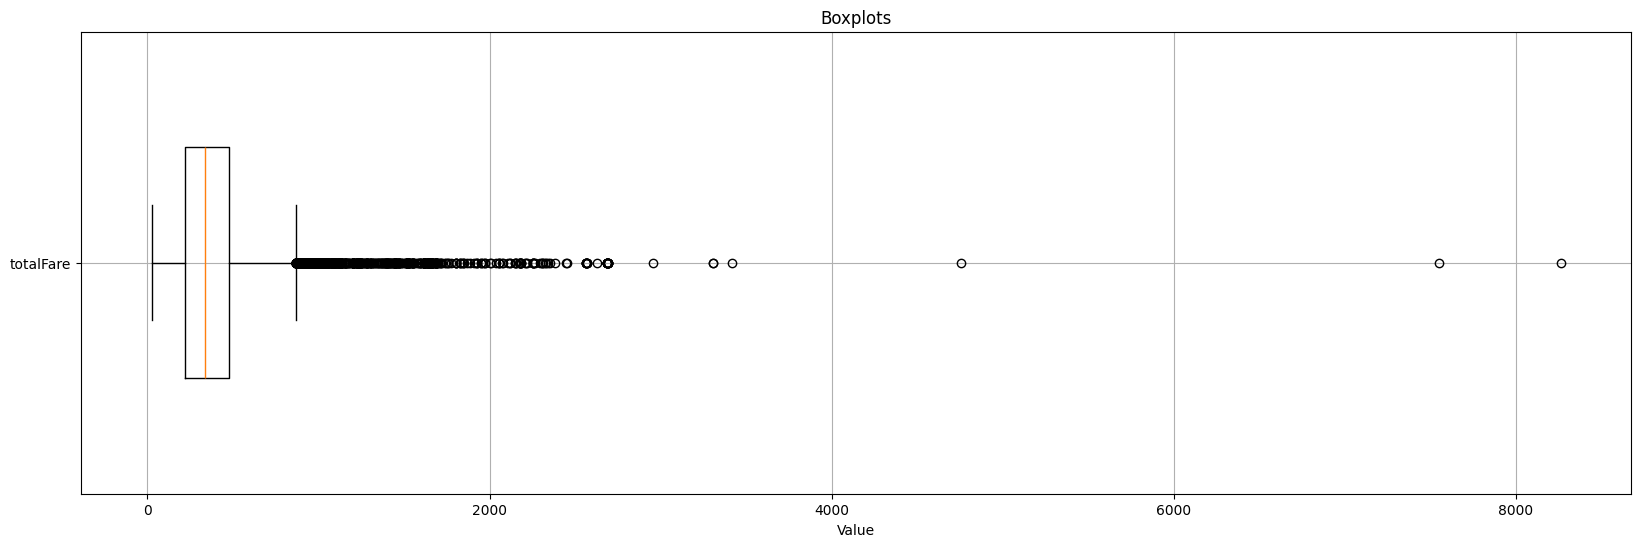

In [80]:
plot_boxplots(data=df, columns=["totalFare"])

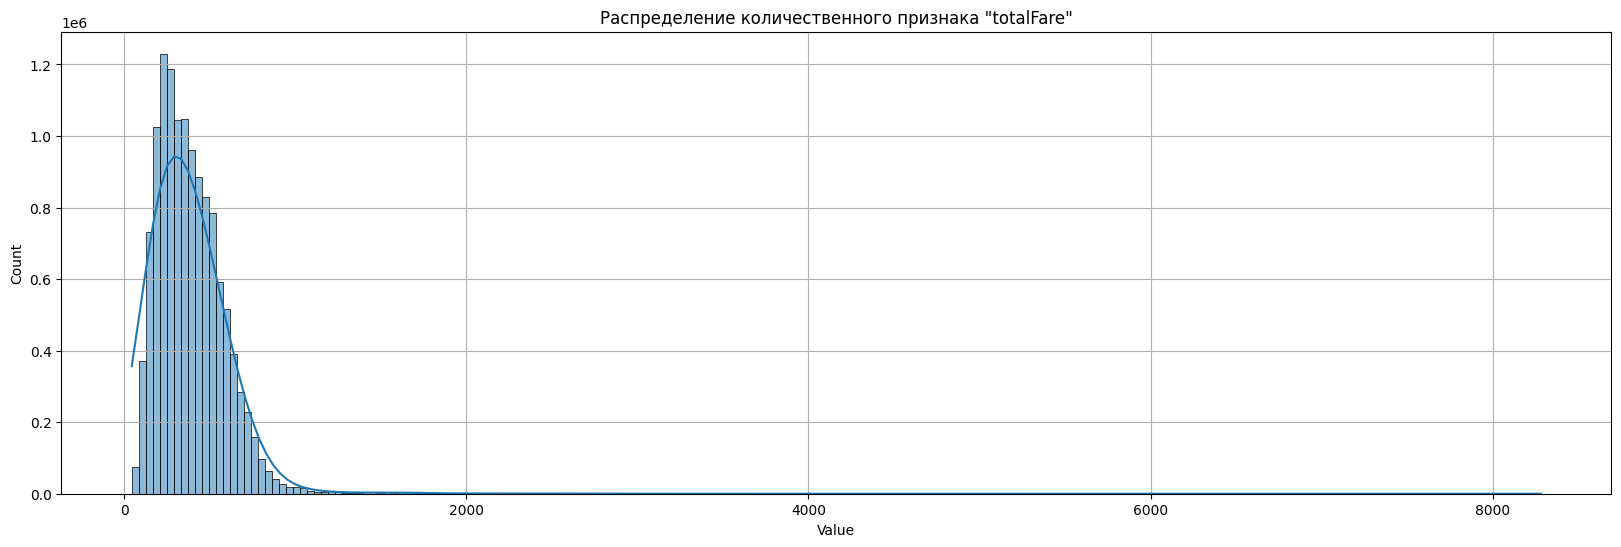

In [81]:
plot_quant_distribution(data=df, column="totalFare")

Как и для других денежных величин, распределение имеет длинный правый «хвост» с небольшим числом очень дорогих билетов. Удалим строки со стоимостью выше 99,5-го процентиля.

Граница (99,5-й процентиль), USD: 907.7100219726562


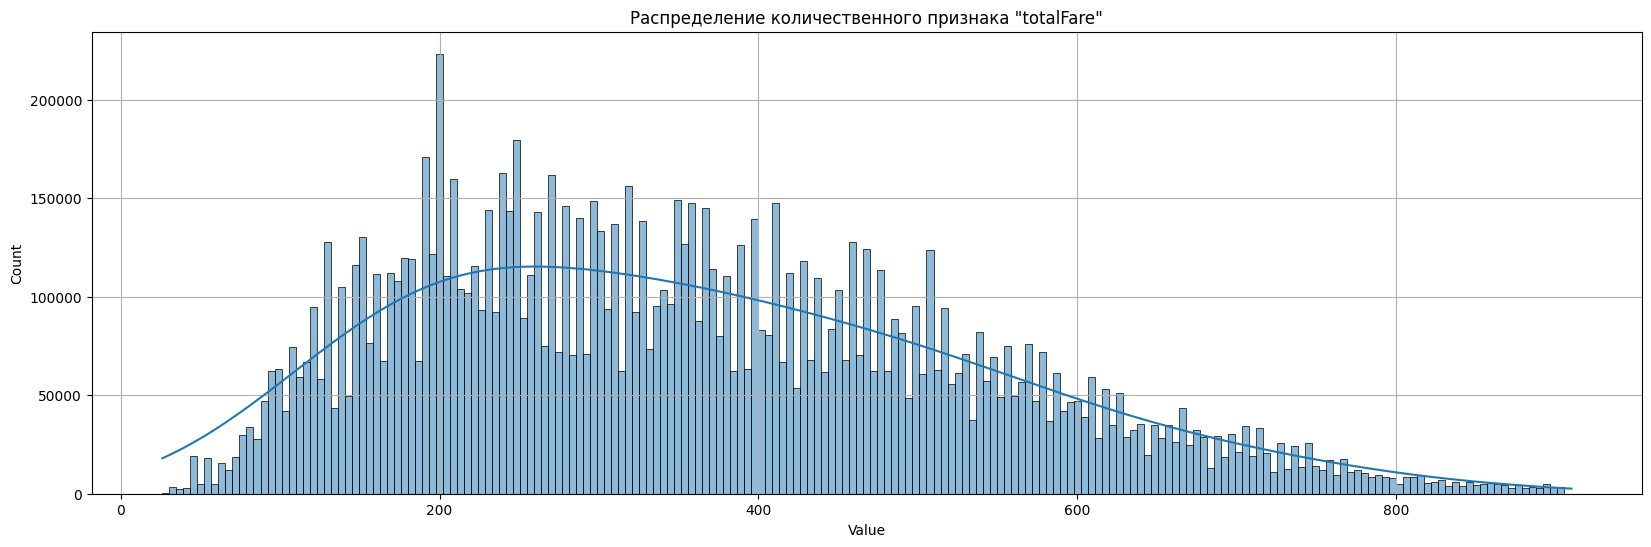

In [94]:
fare_upper = get_upper_quantile(df, "totalFare", q=0.995)
print(f"Граница (99,5-й процентиль), USD: {fare_upper}")

df = df.filter(col("totalFare") <= fare_upper)
plot_quant_distribution(data=df, column="totalFare")

Видно, что цена билета варьируется от 23,97 до 8260,61 долларов при среднем значении 370,21 и медиане 338,60. Распределение сильно скошено вправо: большая часть билетов стоит от 220 до 480 долларов (первый и третий квартили), а единичные билеты стоят дороже 3000 долларов, что явно выбивается из общей массы. Граница по 99,5-му процентилю равна 1122,71 доллара; более дорогие билеты были удалены. После этого распределение остается скошенным вправо, но без экстремальных значений, которые сильно искажали бы обучение линейной регрессии.

#### Расчет корреляции между количественными признаками

In [83]:
def compute_and_visualize_correlation_matrix(data: DataFrame, 
                                             columns: list[str]) -> None:
    """
    Вычисляет и визуализирует корреляционную матрицу для указанных 
    колонок в DataFrame PySpark. Все коэффициенты вычисляются за один 
    проход по данным.

    Args:
        data (DataFrame): DataFrame PySpark.
        columns (list[str]): Список колонок для вычисления корреляции.

    Returns:
        None
    """
    # Вычисляем коэффициенты корреляции для всех пар столбцов за один проход
    pairs = []
    for i, c1 in enumerate(columns):
        for c2 in columns[i + 1:]:
            pairs.append((c1, c2))
    row = data.select(
        [corr(c1, c2).alias(f"{c1}__{c2}") for c1, c2 in pairs]
    ).first()

    # Формируем симметричную корреляционную матрицу
    corr_matrix_pd = pd.DataFrame(1.0, index=columns, columns=columns)
    for c1, c2 in pairs:
        value = row[f"{c1}__{c2}"]
        corr_matrix_pd.loc[c1, c2] = value
        corr_matrix_pd.loc[c2, c1] = value

    # Построение и визуализация корреляционной матрицы
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix_pd, annot=True, cmap='coolwarm', linewidths=0.5)
    plt.title('Correlation Matrix')
    plt.show()

26/10/21 00:09:59 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


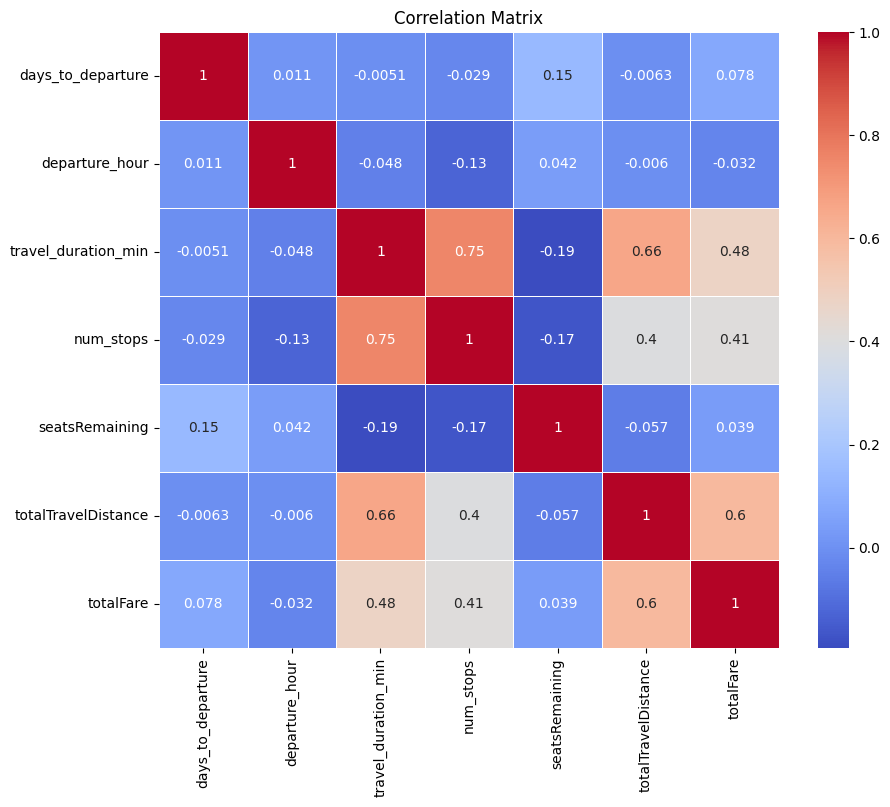

In [84]:
compute_and_visualize_correlation_matrix(
    data=df, columns=[
        "days_to_departure", "departure_hour", "travel_duration_min",
        "num_stops", "seatsRemaining", "totalTravelDistance", "totalFare"
    ]
)

Видно, что наиболее сильно с целевой переменной `totalFare` связаны дальность перелёта `totalTravelDistance` (коэффициент корреляции 0,6), длительность поездки `travel_duration_min` (0,48) и число пересадок `num_stops` (0,41): чем дальше и дольше перелёт, тем он дороже. Связь цены с количеством дней до вылета (0,08), числом оставшихся мест (0,04) и часом вылета (−0,03) линейно почти не проявляется. Между самими признаками есть сильная корреляция: длительность поездки тесно связана с числом пересадок (0,75) и с дальностью (0,66). Для линейной регрессии это означает мультиколлинеарность, из-за которой коэффициенты при этих признаках могут быть нестабильными.

#### Категориальные признаки и их кодирование для линейной модели

В лабораторной работе № 2 для задачи линейной регрессии все категориальные признаки с небольшим числом категорий необходимо закодировать `one-hot`-кодировкой. Линейная модель не может работать с номерами категорий напрямую: например, закодировав аэропорты числами от 0 до 15, мы бы навязали модели несуществующий порядок и «расстояния» между аэропортами. При `one-hot`-кодировании каждая категория превращается в отдельный бинарный столбец, поэтому количество категорий напрямую определяет размерность вектора признаков.

Категориальными признаками в нашем датасете являются:
* `startingAirport`, `destinationAirport` — аэропорты;
* `main_airline` — авиакомпания;
* `flight_month`, `flight_dayofweek` — месяц и день недели вылета (числовые значения, но по смыслу категории).

Класс обслуживания `main_cabin` на предыдущем этапе был удален как практически константный признак.

Оценим число категорий каждого признака и размер получающегося вектора после кодирования (с отбрасыванием одной категории, `dropLast=True`, чтобы избежать мультиколлинеарности).

In [87]:
import builtins
categorical_columns = [
    c for c in ["startingAirport", "destinationAirport", "main_airline",
                "main_cabin", "flight_month", "flight_dayofweek"]
    if c in df.columns   
]

cardinality = df.agg(
    *[countDistinct(c).alias(c) for c in categorical_columns]
).first().asDict()

for column, n_categories in cardinality.items():
    rarest = (
        df.groupBy(column).count()
        .orderBy("count")
        .first()
    )
    print(f"{column:20s} категорий: {n_categories:3d}, "
          f"самая редкая: {rarest[0]} ({rarest['count']} строк)")

total_dims = builtins.sum(n - 1 for n in cardinality.values())
print(f"\nРазмерность вектора после one-hot (dropLast=True): {total_dims}")

startingAirport      категорий:  16, самая редкая: OAK (471617 строк)


destinationAirport   категорий:  16, самая редкая: OAK (445743 строк)


main_airline         категорий:   9, самая редкая: Sun Country Airlines (22578 строк)


flight_month         категорий:   4, самая редкая: 7 (471214 строк)


flight_dayofweek     категорий:   7, самая редкая: 1 (1593899 строк)

Размерность вектора после one-hot (dropLast=True): 47


Видно, что число категорий невелико (от 4 до 16), самые редкие категории представлены достаточным количеством объектов (например, самая редкая авиакомпания `Sun Country Airlines` — 22 578 строк, самый редкий месяц вылета — июль, 471 186 строк), а суммарная размерность вектора признаков остается небольшой (47). Поэтому `one-hot`-кодирование для линейной модели вполне применимо. Именно для этого на предыдущих этапах мы объединили редкие авиакомпании в категорию `Other` и удалили почти константный признак `main_cabin`: без этого получились бы столбцы, почти целиком состоящие из нулей.

Само кодирование будет выполнено в лабораторной работе № 2, поскольку оно нужно только линейной модели. В сохраняемой таблице категориальные признаки остаются в исходном виде, чтобы эту же таблицу можно было использовать и для градиентного бустинга на деревьях решений, которому достаточно `label encoding`. Числовые `flight_month` и `flight_dayofweek` перед `one-hot`-кодированием обрабатываются как категории.

#### Итоговый датасет

Упорядочим столбцы: идентификатор, признаки, а в конце целевые переменные.

In [88]:
final_columns = [
    "legId", "startingAirport", "destinationAirport",
    "flight_month", "flight_dayofweek", "days_to_departure", "departure_hour",
    "travel_duration_min", "num_stops", "isNonStop", "arrives_later_day",
    "main_airline", "seatsRemaining", "totalTravelDistance",
    "isBasicEconomy", "totalFare"
]

df = df.select([c for c in final_columns if c in df.columns])
df.show(5, truncate=40)

+--------------------------------+---------------+------------------+------------+----------------+-----------------+--------------+-------------------+---------+---------+-----------------+-----------------+--------------+-------------------+--------------+---------+
|                           legId|startingAirport|destinationAirport|flight_month|flight_dayofweek|days_to_departure|departure_hour|travel_duration_min|num_stops|isNonStop|arrives_later_day|     main_airline|seatsRemaining|totalTravelDistance|isBasicEconomy|totalFare|
+--------------------------------+---------------+------------------+------------+----------------+-----------------+--------------+-------------------+---------+---------+-----------------+-----------------+--------------+-------------------+--------------+---------+
|a0ae8d5727fd9f58d23ec3469b0bf2d1|            PHL|               ATL|           5|               6|               25|             6|                247|        1|    false|            false|Ame

Проверим, что пропуски в итоговом датасете отсутствуют.

In [89]:
null_summary(df)

,nulls,nulls_pct
legId,0,0.0
startingAirport,0,0.0
destinationAirport,0,0.0
flight_month,0,0.0
flight_dayofweek,0,0.0
days_to_departure,0,0.0
departure_hour,0,0.0
travel_duration_min,0,0.0
num_stops,0,0.0
isNonStop,0,0.0


Посмотрим, сколько объектов осталось после преобразований датасета.

In [90]:
df.count()

12637448

Итого после всех преобразований в датасете осталось 12 637 448 строк из исходных 12 857 310 (удалено около 1,7 %). Все удаленные строки — это отсеченные выбросы: по длительности поездки около 74 тысяч строк, а по дальности и цене суммарно около 146 тысяч. Пропусков и дубликатов не осталось, признаки имеют корректные типы, а датасет готов к использованию во второй лабораторной работе.

In [91]:
df.printSchema()

root
 |-- legId: string (nullable = true)
 |-- startingAirport: string (nullable = true)
 |-- destinationAirport: string (nullable = true)
 |-- flight_month: integer (nullable = true)
 |-- flight_dayofweek: integer (nullable = true)
 |-- days_to_departure: integer (nullable = true)
 |-- departure_hour: integer (nullable = true)
 |-- travel_duration_min: integer (nullable = true)
 |-- num_stops: integer (nullable = false)
 |-- isNonStop: boolean (nullable = true)
 |-- arrives_later_day: boolean (nullable = false)
 |-- main_airline: string (nullable = true)
 |-- seatsRemaining: integer (nullable = true)
 |-- totalTravelDistance: float (nullable = false)
 |-- isBasicEconomy: boolean (nullable = true)
 |-- totalFare: float (nullable = true)



Описание столбцов итогового датасета:

| Название столбца    | Расшифровка | Тип признака |
| ------------------- | ----------- | ------------ |
| legId               | Идентификатор перелёта (не уникален: один перелёт мог наблюдаться в разные дни поиска). В качестве признака в моделях не используется | идентификатор |
| startingAirport     | Аэропорт вылета | категориальный, 16 категорий |
| destinationAirport  | Аэропорт прилёта | категориальный, 16 категорий |
| flight_month        | Месяц вылета (4 — апрель, ..., 7 — июль) | категориальный (порядковый), 4 значения |
| flight_dayofweek    | День недели вылета (1 — воскресенье, 7 — суббота) | категориальный (порядковый), 7 значений |
| days_to_departure   | Количество дней от даты поиска до даты вылета | количественный, дискретный, [1, 60] |
| departure_hour      | Час вылета по местному времени | количественный, дискретный, [0, 23] |
| travel_duration_min | Длительность поездки в минутах | количественный, непрерывный |
| num_stops           | Количество пересадок | количественный, дискретный, [0, 3] |
| isNonStop           | Прямой ли перелёт | бинарный |
| arrives_later_day   | Происходит ли прилёт не в день вылета | бинарный |
| main_airline        | Авиакомпания первого сегмента (редкие объединены в `Other`) | категориальный, 9 категорий |
| seatsRemaining      | Количество оставшихся мест | количественный, дискретный, [0, 10] |
| totalTravelDistance | Общая дальность перелёта в милях | количественный, непрерывный |
| isBasicEconomy      | Билет базовой экономии | бинарный, **целевая переменная** классификации |
| totalFare           | Итоговая цена билета, USD | количественный, непрерывный, **целевая переменная** регрессии |

Столбцы `isRefundable` и `main_cabin` в ходе очистки были удалены, так как практически все их значения одинаковы.

Сохраняем очищенную и обработанную таблицу на диск.

In [92]:
# Сохранение DataFrame в виде таблицы
df.writeTo("sobd_lab1_processed_table").using("iceberg").createOrReplace()

26/10/21 00:24:13 WARN HadoopTableOperations: Error reading version hint file hdfs:/user/user0/warehouse/alieva_SAPR_database/sobd_lab1_processed_table/metadata/version-hint.text
java.io.FileNotFoundException: File does not exist: /user/user0/warehouse/alieva_SAPR_database/sobd_lab1_processed_table/metadata/version-hint.text
	at org.apache.hadoop.hdfs.server.namenode.INodeFile.valueOf(INodeFile.java:87)
	at org.apache.hadoop.hdfs.server.namenode.INodeFile.valueOf(INodeFile.java:77)
	at org.apache.hadoop.hdfs.server.namenode.FSDirStatAndListingOp.getBlockLocations(FSDirStatAndListingOp.java:159)
	at org.apache.hadoop.hdfs.server.namenode.FSNamesystem.getBlockLocations(FSNamesystem.java:2198)
	at org.apache.hadoop.hdfs.server.namenode.NameNodeRpcServer.getBlockLocations(NameNodeRpcServer.java:795)
	at org.apache.hadoop.hdfs.protocolPB.ClientNamenodeProtocolServerSideTranslatorPB.getBlockLocations(ClientNamenodeProtocolServerSideTranslatorPB.java:468)
	at org.apache.hadoop.hdfs.protocol.p

In [95]:
for table in spark.catalog.listTables():
    print(table.name)

sobd_lab1_processed_table
sobd_lab1_table


Обратите внимание, что при необходимости созданные базу данных и таблицу можно удалить следующими командами.

In [ ]:
# spark.sql("DROP TABLE spark_catalog.alieva_SAPR_database.sobd_lab1_processed_table")
# spark.sql("DROP DATABASE spark_catalog.alieva_SAPR_database")

DataFrame[]

Останавливаем `Spark`-сессию.

In [96]:
spark.stop()